# ЛР1. Предобработка данных

**Датасет:** Credit Score Classification  
**Выполнил(а):** Быков Лев

**Группа:** P3319

## 0. Постановка задачи

### 1. Датасет

Набор содержит помесячные финансовые сведения о клиентах банка. В архиве две таблицы:

- `train.csv` — январь–август, 100 000 наблюдений и целевая переменная `Credit_Score`;
- `test.csv` — сентябрь–декабрь, 50 000 наблюдений без целевой переменной;
- один клиент встречается несколько раз, поэтому единица наблюдения — **клиент в конкретном месяце**;
- целевой класс принимает значения `Good`, `Standard`, `Poor`.

Признаки описывают доход, кредитную нагрузку, задержки платежей, кредитную историю, поведение при оплате и остаток средств.

### 2. Цель

**Цель проекта (ЛР1–ЛР3):** выявить топ-5 факторов, сильнее всего связанных с `Credit_Score` (по размеру эффекта в статистических тестах и по permutation importance модели), и построить классификатор, который на клиентах, не участвовавших в обучении, превосходит наивный бейзлайн («всегда `Standard`») по macro-F1.

**Цель ЛР1:** Подготовить согласованный набор данных для последующей классификации кредитного рейтинга: выявить пропуски и технические маркеры, исправить типы, обработать аномалии, восстановить стабильные характеристики клиента и создать интерпретируемые признаки.

### 3. Задачи

1. Изучить структуру `train` и `test`, типы, пропуски, дубликаты и баланс классов.
2. Найти неявные пропуски и значения, нарушающие предметные ограничения.
3. Использовать повторные наблюдения клиента для восстановления стабильных признаков.
4. Обработать меняющиеся во времени признаки без использования целевой переменной.
5. Удалить персональные и технические поля, сформировать дополнительные категории.
6. Проверить результат и сохранить очищенные таблицы.

### 4. Гипотезы для дальнейшего анализа

1. Больший долг и более длительные просрочки связаны с худшим `Credit_Score`.
2. Высокая процентная ставка чаще встречается у клиентов с рейтингом `Poor`.
3. Категория `Credit_Mix = Bad` связана с худшим рейтингом.
4. Частые кредитные запросы связаны с ухудшением рейтинга.
5. Большая доля EMI-платежей в месячном доходе связана с худшим рейтингом.

Это наблюдательные гипотезы: обнаруженная связь сама по себе не доказывает причинность.

### 5. Источник данных и ограничения

- **Источник:** открытый набор *Credit score classification* на Kaggle (автор публикации — Rohan Paris, 2022), файл `archive.zip` с таблицами `train.csv` и `test.csv`.
- **Как собирались:** по описанию автора — сведения о клиентах глобальной финансовой компании, собранные из банковских и кредитных записей за 12 месяцев; присвоение `Credit_Score` выполнено сотрудниками/внутренней системой компании. Методика присвоения рейтинга не раскрыта.
- **Ограничения:**
  - данные, по всей видимости, **частично синтетические и намеренно «зашумлены»** для учебных целей: подчёркивания в числах, служебные маркеры, значения вроде `-500` лет и $-3.3\cdot10^{26}$;
  - **не указаны валюта и регион**, поэтому денежные признаки далее измеряются в условных денежных единицах (у.е.);
  - нет описания, на какую дату считается `Credit_History_Age` и как вычисляется `Changed_Credit_Limit`;
  - `test.csv` не содержит целевой переменной, поэтому качество моделей можно оценить только на отложенной части `train`;
  - наблюдения одного клиента за разные месяцы **зависимы** — это нужно учитывать в статистических тестах и при разбиении выборки.


## Установка необходимых библиотек

Перед первым запуском проверим окружение. Если нужных библиотек нет, следующая ячейка установит их в текущий Python-интерпретатор. Уже установленные пакеты повторно не загружаются.

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib"}
missing_packages = [pip_name for module, pip_name in REQUIRED.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
print("Все библиотеки доступны" if not missing_packages else f"Установлено: {missing_packages}")

Все библиотеки доступны


## 1. Обзор данных

Загружаем обе таблицы из `archive.zip` (`train.csv`, `test.csv`). Исходники лежат в `dataset-intro/data` – из этой папки ноутбук их и читает; копия в `data/` рядом с ноутбуком тоже подойдёт.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
plt.style.use("seaborn-v0_8-whitegrid")

candidates = [
    Path("data"),
    Path("../dataset-intro") / "data",
    Path("dataset-intro") / "data",
]
data_dir = next((p for p in candidates if (p / "train.csv").exists()), None)
if data_dir is None:
    raise FileNotFoundError("Распакуйте archive.zip в папку dataset-intro/data рядом с ноутбуком")

train_raw = pd.read_csv(data_dir / "train.csv", low_memory=False)
test_raw = pd.read_csv(data_dir / "test.csv", low_memory=False)

print("Папка с данными:", data_dir.resolve())
print("train:", train_raw.shape, "test:", test_raw.shape)

Папка с данными: /home/undndnwnkk/dev/university-works/data-analysis-3rd-course/dataset-intro/data
train: (100000, 28) test: (50000, 27)


### 1.1. Словарь основных признаков

| Признак | Смысл |
|---|---|
| `Customer_ID`, `Month` | клиент и месяц наблюдения |
| `Age`, `Occupation`, `Annual_Income` | возраст, профессия, годовой доход |
| `Monthly_Inhand_Salary` | ежемесячный доход после удержаний |
| `Num_Bank_Accounts`, `Num_Credit_Card` | количество счетов и кредитных карт |
| `Interest_Rate`, `Num_of_Loan`, `Type_of_Loan` | ставка, число и типы кредитов |
| `Delay_from_due_date`, `Num_of_Delayed_Payment` | просрочка и число задержанных платежей |
| `Outstanding_Debt` | непогашенная задолженность |
| `Credit_Utilization_Ratio` | доля использования кредитного лимита |
| `Credit_History_Age` | длительность кредитной истории |
| `Total_EMI_per_month` | ежемесячные платежи по кредитам |
| `Amount_invested_monthly`, `Monthly_Balance` | инвестиции и остаток за месяц |
| `Payment_Behaviour` | сочетание уровня трат и размера платежей |
| `Credit_Score` | целевой кредитный рейтинг |

In [3]:
train_raw.head(10)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4.0,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,NaN,11.27,4.0,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good
5,0x1607,CUS_0xd40,June,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",8,4,9.27,4.0,Good,809.98,27.262259,22 Years and 6 Months,No,49.574949,62.430172331195294,!@9#%8,340.4792117872438,Good
6,0x1608,CUS_0xd40,July,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,8_,11.27,4.0,Good,809.98,22.537593,22 Years and 7 Months,No,49.574949,178.3440674122349,Low_spent_Small_value_payments,244.5653167062043,Good
7,0x1609,CUS_0xd40,August,NaN,23,#F%$D@*&8,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,6,11.27,4.0,Good,809.98,23.933795,NaN,No,49.574949,24.785216509052056,High_spent_Medium_value_payments,358.12416760938714,Standard
8,0x160e,CUS_0x21b1,January,Rick Rothackerj,28_,004-07-5839,_______,34847.84,3037.986667,2,4,6,1,Credit-Builder Loan,3,4,5.42,2.0,Good,605.03,24.464031,26 Years and 7 Months,No,18.816215,104.291825168246,Low_spent_Small_value_payments,470.69062692529184,Standard
9,0x160f,CUS_0x21b1,February,Rick Rothackerj,28,004-07-5839,Teacher,34847.84,3037.986667,2,4,6,1,Credit-Builder Loan,7,1,7.42,2.0,Good,605.03,38.550848,26 Years and 8 Months,No,18.816215,40.39123782853101,High_spent_Large_value_payments,484.5912142650067,Good


In [4]:
overview = pd.DataFrame({
    "train_type": train_raw.dtypes.astype(str),
    "train_non_null": train_raw.notna().sum(),
    "train_unique": train_raw.nunique(dropna=True),
    "test_type": test_raw.dtypes.astype(str),
    "test_non_null": test_raw.notna().sum(),
    "test_unique": test_raw.nunique(dropna=True),
})
overview

,train_type,train_non_null,train_unique,test_type,test_non_null,test_unique
Age,str,100000,1788,str,50000.0,976.0
Amount_invested_monthly,str,95521,91049,str,47729.0,45450.0
Annual_Income,str,100000,18940,str,50000.0,16121.0
Changed_Credit_Limit,str,100000,4384,str,50000.0,3927.0
Credit_History_Age,str,90970,404,str,45530.0,399.0
Credit_Mix,str,100000,4,str,50000.0,4.0
Credit_Score,str,100000,3,NaN,NaN,NaN
Credit_Utilization_Ratio,float64,100000,100000,float64,50000.0,50000.0
Customer_ID,str,100000,12500,str,50000.0,12500.0
Delay_from_due_date,int64,100000,73,int64,50000.0,73.0


In [5]:
missing = pd.DataFrame({
    "train_missing": train_raw.isna().sum(),
    "train_missing_%": train_raw.isna().mean().mul(100).round(2),
    "test_missing": test_raw.isna().sum(),
    "test_missing_%": test_raw.isna().mean().mul(100).round(2),
}).sort_values("train_missing", ascending=False)
missing[missing.max(axis=1) > 0]

,train_missing,train_missing_%,test_missing,test_missing_%
Monthly_Inhand_Salary,15002,15.00,7498.0,15.00
Type_of_Loan,11408,11.41,5704.0,11.41
Name,9985,9.98,5015.0,10.03
Credit_History_Age,9030,9.03,4470.0,8.94
Num_of_Delayed_Payment,7002,7.00,3498.0,7.00
Amount_invested_monthly,4479,4.48,2271.0,4.54
Num_Credit_Inquiries,1965,1.96,1035.0,2.07
Monthly_Balance,1200,1.20,562.0,1.12


In [6]:
print("Полных дублей train:", train_raw.duplicated().sum())
print("Полных дублей test:", test_raw.duplicated().sum())
print("Уникальных ID train:", train_raw["ID"].nunique())
print("Уникальных клиентов train:", train_raw["Customer_ID"].nunique())
print("Уникальных клиентов test:", test_raw["Customer_ID"].nunique())
print("Клиентов только в test:", len(set(test_raw["Customer_ID"]) - set(train_raw["Customer_ID"])))
print("\nЧисло строк на клиента в train:")
print(train_raw.groupby("Customer_ID").size().value_counts().sort_index())

Полных дублей train: 0
Полных дублей test: 0
Уникальных ID train: 100000
Уникальных клиентов train: 12500
Уникальных клиентов test: 12500
Клиентов только в test: 0

Число строк на клиента в train:
8    12500
Name: count, dtype: int64


,наблюдений,"доля, %"
Credit_Score,,
Standard,53174,53.17
Poor,28998,29.00
Good,17828,17.83


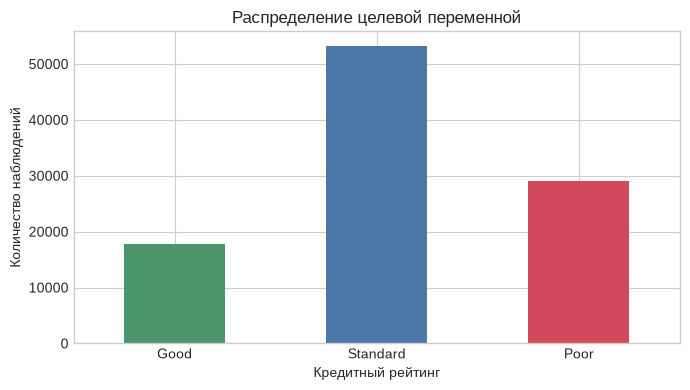

In [7]:
target_counts = train_raw["Credit_Score"].value_counts()
target_share = train_raw["Credit_Score"].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({"наблюдений": target_counts, "доля, %": target_share}))

ax = target_counts.reindex(["Good", "Standard", "Poor"]).plot(
    kind="bar", color=["#4c956c", "#4c78a8", "#d1495b"], figsize=(7, 4)
)
ax.set_title("Распределение целевой переменной")
ax.set_xlabel("Кредитный рейтинг")
ax.set_ylabel("Количество наблюдений")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 1.2. Неявные пропуски и повреждённые значения

Обычный `isna()` не видит служебные маркеры. Проверим строки с подчёркиваниями и известные бессмысленные категории. Подчёркивание внутри `Customer_ID` и названий вроде `Media_Manager` является частью корректного значения, поэтому учитываем контекст каждого поля.

In [8]:
technical_markers = {
    "Occupation": ["_______"],
    "Credit_Mix": ["_"],
    "Changed_Credit_Limit": ["_"],
    "Payment_Behaviour": ["!@9#%8"],
    "SSN": ["#F%$D@*&8"],
    "Payment_of_Min_Amount": ["NM"],
}

marker_rows = []
for column, markers in technical_markers.items():
    marker_rows.append({
        "признак": column,
        "маркеры": ", ".join(markers),
        "train": train_raw[column].isin(markers).sum(),
        "test": test_raw[column].isin(markers).sum(),
    })

suffix_columns = [
    "Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment",
    "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance",
]
for column in suffix_columns:
    marker_rows.append({
        "признак": column,
        "маркеры": "число с суффиксом _",
        "train": train_raw[column].astype("string").str.endswith("_", na=False).sum(),
        "test": test_raw[column].astype("string").str.endswith("_", na=False).sum(),
    })

pd.DataFrame(marker_rows)

,признак,маркеры,train,test
0,Occupation,_______,7062,3438
1,Credit_Mix,_,20195,9805
2,Changed_Credit_Limit,_,2091,1059
3,Payment_Behaviour,!@9#%8,7600,3800
4,SSN,#F%$D@*&8,5572,2828
5,Payment_of_Min_Amount,NM,12007,5993
6,Age,число с суффиксом _,4939,2477
7,Annual_Income,число с суффиксом _,6980,3520
8,Num_of_Loan,число с суффиксом _,4785,2436
9,Num_of_Delayed_Payment,число с суффиксом _,2744,1427


In [9]:
raw_numeric_columns = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date",
    "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries",
    "Outstanding_Debt", "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance",
]

def numeric_view(series):
    return pd.to_numeric(
        series.astype("string").str.replace("_", "", regex=False), errors="coerce"
    )

raw_ranges = []
for column in raw_numeric_columns:
    values = numeric_view(train_raw[column])
    raw_ranges.append({
        "признак": column,
        "пропусков после преобразования": values.isna().sum(),
        "min": values.min(),
        "медиана": values.median(),
        "p99": values.quantile(0.99),
        "max": values.max(),
    })
pd.DataFrame(raw_ranges).set_index("признак").round(2)

,пропусков после преобразования,min,медиана,p99,max
признак,,,,,
Age,0,-5.000000e+02,33.00,4112.07,8698.00
Annual_Income,0,7.005930e+03,37578.61,179987.28,24198062.00
Monthly_Inhand_Salary,15002,3.036500e+02,3093.75,13814.93,15204.63
Num_Bank_Accounts,0,-1.000000e+00,6.00,445.01,1798.00
Num_Credit_Card,0,0.000000e+00,5.00,849.00,1499.00
Interest_Rate,0,1.000000e+00,13.00,2865.01,5797.00
Num_of_Loan,0,-1.000000e+02,3.00,9.00,1496.00
Delay_from_due_date,0,-5.000000e+00,18.00,61.00,67.00
Num_of_Delayed_Payment,7002,-3.000000e+00,14.00,27.00,4397.00


### 1.3. Базовые статистики

`describe()` по исходным строковым полям бесполезен, поэтому считаем статистики по числовому представлению (подчёркивания удалены, но аномалии ещё **не** исправлены). Большое расхождение `mean` и `median` и огромный `std` — первый признак ошибок ввода.

In [10]:
raw_numeric = pd.DataFrame({column: numeric_view(train_raw[column]) for column in raw_numeric_columns})
raw_stats = raw_numeric.agg(["mean", "median", "std", "min", "max"]).T
raw_stats["mean / median"] = raw_stats["mean"] / raw_stats["median"]
raw_stats.style.format("{:,.2f}")

,mean,median,std,min,max,mean / median
Age,110.65,33.00,686.24,-500.00,"8,698.00",3.35
Annual_Income,"176,415.70","37,578.61","1,429,618.05","7,005.93","24,198,062.00",4.69
Monthly_Inhand_Salary,"4,194.17","3,093.75","3,183.69",303.65,"15,204.63",1.36
Num_Bank_Accounts,17.09,6.00,117.40,-1.00,"1,798.00",2.85
Num_Credit_Card,22.47,5.00,129.06,0.00,"1,499.00",4.49
Interest_Rate,72.47,13.00,466.42,1.00,"5,797.00",5.57
Num_of_Loan,3.01,3.00,62.65,-100.00,"1,496.00",1.00
Delay_from_due_date,21.07,18.00,14.86,-5.00,67.00,1.17
Num_of_Delayed_Payment,30.92,14.00,226.03,-3.00,"4,397.00",2.21
Changed_Credit_Limit,10.39,9.40,6.79,-6.49,36.97,1.11


### 1.4. Первичные распределения (до очистки)

Простые гистограммы по исходным числовым значениям. Ось Y логарифмическая, иначе редкие аномалии не видны на фоне основной массы.

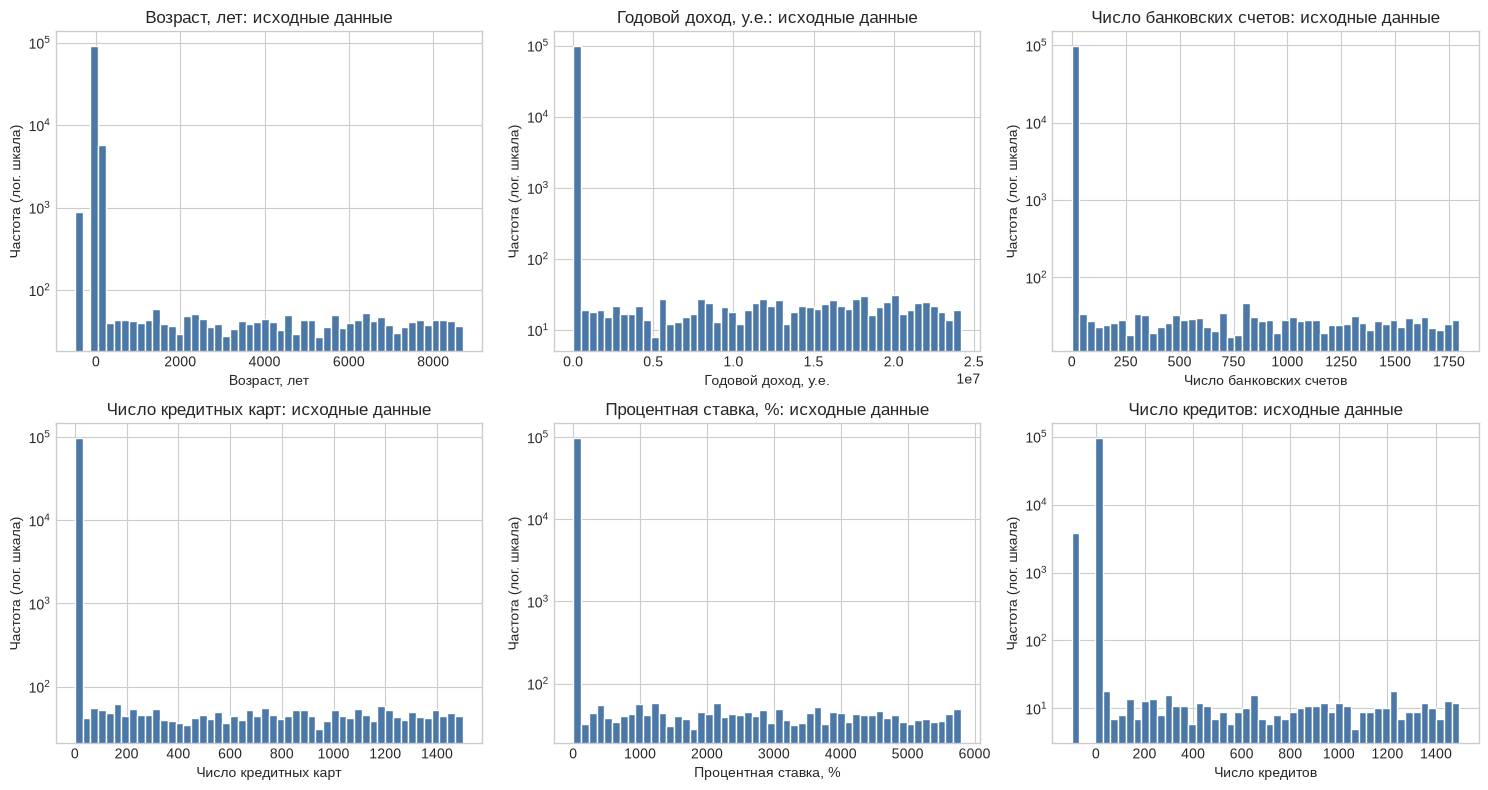

In [11]:
raw_hist_columns = [
    ("Age", "Возраст, лет"),
    ("Annual_Income", "Годовой доход, у.е."),
    ("Num_Bank_Accounts", "Число банковских счетов"),
    ("Num_Credit_Card", "Число кредитных карт"),
    ("Interest_Rate", "Процентная ставка, %"),
    ("Num_of_Loan", "Число кредитов"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (column, label) in zip(axes.flat, raw_hist_columns):
    ax.hist(raw_numeric[column].dropna(), bins=50, color="#4c78a8", edgecolor="white")
    ax.set_yscale("log")
    ax.set_title(f"{label}: исходные данные")
    ax.set_xlabel(label)
    ax.set_ylabel("Частота (лог. шкала)")
plt.tight_layout()
plt.show()

### Наблюдения по исходным данным

- `train` содержит 100 000 строк и 28 полей, `test` — 50 000 строк и 27 полей.
- 12 500 клиентов представлены ровно восемью месяцами в `train` и четырьмя в `test`; это позволяет восстанавливать стабильные признаки по клиенту.
- Полных дублей нет, `ID` уникален.
- Цель несбалансирована умеренно: `Standard` — 53.17%, `Poor` — 29.00%, `Good` — 17.83%.
- Помимо обычных пропусков есть технические маркеры `_`, `_______`, `!@9#%8`, числовые строки с завершающим `_`.
- В `Payment_of_Min_Amount` 12 007 строк (12%) имеют значение `NM` (*not mentioned*) — это неявный пропуск.
- По гистограммам основная масса значений лежит в правдоподобном диапазоне, а аномалии — редкие изолированные значения на порядки больше (длинный «хвост» на лог. шкале). Это ошибки ввода, а не естественная изменчивость.
- Диапазоны показывают ошибки ввода: возраст `-500` и тысячи лет, сотни счетов/карт, огромные ставки, EMI и отрицательный остаток порядка $10^{26}$.
- Поля `Name` и `SSN` содержат персональные данные и не нужны для модели; `ID` — технический идентификатор.

## 2. Предобработка

### 2.1. Стратегия

Предобработка разделена на два этапа.

1. **Базовая очистка:** технические маркеры заменяются на `NaN`, числовые строки переводятся в числа, кредитная история — в месяцы, невозможные значения отбрасываются.
2. **Восстановление:** стабильные признаки берутся как наиболее частое корректное значение того же клиента в `train`; меняющиеся показатели заполняются медианой клиента из `train`, затем медианой/модой всего `train`.

Целевая переменная при заполнении не используется. Профили строятся только по обучающей части, поэтому информация из `test` не влияет на подготовку `train`.

**`NM` в `Payment_of_Min_Amount`** оставляем отдельной категорией (специальная метка), а не заполняем модой: это 12% строк, и заполнение `Yes` исказило бы распределение. Факт «клиент не указал» сам может нести информацию о риске — это проверим в EDA.

In [12]:
MONTH_NUMBER = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12,
}

NUMERIC_COLUMNS = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date",
    "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries",
    "Outstanding_Debt", "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance",
]

VALID_RANGES = {
    "Age": (14, 100),
    "Annual_Income": (1, 1_000_000),
    "Monthly_Inhand_Salary": (0, 100_000),
    "Num_Bank_Accounts": (0, 20),
    "Num_Credit_Card": (0, 20),
    "Interest_Rate": (0, 50),
    "Num_of_Loan": (0, 20),
    "Num_of_Delayed_Payment": (0, 100),
    "Changed_Credit_Limit": (-10, 50),
    "Num_Credit_Inquiries": (0, 50),
    "Outstanding_Debt": (0, 100_000),
    "Credit_Utilization_Ratio": (0, 100),
    "Total_EMI_per_month": (0, 100_000),
    "Amount_invested_monthly": (0, 9_999.99),
    "Monthly_Balance": (0, 1_000_000),
}

def parse_history_months(series):
    text = series.astype("string")
    years = pd.to_numeric(text.str.extract(r"(\d+)\s+Years", expand=False), errors="coerce")
    months = pd.to_numeric(text.str.extract(r"(\d+)\s+Months", expand=False), errors="coerce")
    return years * 12 + months

def basic_clean(frame):
    result = frame.copy()

    for column in result.select_dtypes(include=["object", "string"]).columns:
        result[column] = result[column].astype("string").str.strip()

    result["Occupation"] = result["Occupation"].replace("_______", pd.NA)
    result["Credit_Mix"] = result["Credit_Mix"].replace("_", pd.NA)
    result["Payment_Behaviour"] = result["Payment_Behaviour"].replace("!@9#%8", pd.NA)

    for column in NUMERIC_COLUMNS:
        result[column] = pd.to_numeric(
            result[column].astype("string").str.replace("_", "", regex=False),
            errors="coerce",
        ).astype("float64")

    result["Credit_History_Months_raw"] = parse_history_months(result["Credit_History_Age"])
    result["Month_Number"] = result["Month"].map(MONTH_NUMBER)

    for column, (lower, upper) in VALID_RANGES.items():
        result.loc[~result[column].between(lower, upper), column] = np.nan

    # Отрицательная просрочка означает оплату до срока: для шкалы риска это 0 дней просрочки.
    result["Delay_from_due_date"] = result["Delay_from_due_date"].clip(lower=0)

    # Значение 10000 в инвестициях — известная числовая заглушка и исключено границей выше.
    return result

train_stage = basic_clean(train_raw)
test_stage = basic_clean(test_raw)

### 2.2. Стабильные признаки клиента

Возраст, профессия, доход, число счетов/карт, ставка, кредиты и долг не должны случайно меняться каждый месяц. После удаления невозможных значений заменяем их модой клиента в `train`. Для числовых полей при равенстве частот берётся медиана кандидатов. Такой подход устойчив к одиночным повреждениям и использует структуру панели данных.

In [13]:
STABLE_NUMERIC = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
    "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Outstanding_Debt",
]
STABLE_CATEGORICAL = ["Occupation", "Type_of_Loan", "Credit_Mix"]

def numeric_mode(series):
    values = series.dropna()
    if values.empty:
        return np.nan
    modes = values.mode()
    return float(modes.median())

def categorical_mode(series):
    values = series.dropna()
    if values.empty:
        return pd.NA
    return values.mode().iloc[0]

numeric_profile = train_stage.groupby("Customer_ID")[STABLE_NUMERIC].agg(numeric_mode)
categorical_profile = train_stage.groupby("Customer_ID")[STABLE_CATEGORICAL].agg(categorical_mode)

global_numeric = train_stage[STABLE_NUMERIC].median()
global_categorical = {
    column: categorical_mode(train_stage[column]) for column in STABLE_CATEGORICAL
}

def apply_stable_profile(frame):
    result = frame.copy()
    for column in STABLE_NUMERIC:
        mapped = result["Customer_ID"].map(numeric_profile[column])
        result[column] = mapped.fillna(global_numeric[column])
    for column in STABLE_CATEGORICAL:
        mapped = result["Customer_ID"].map(categorical_profile[column])
        result[column] = mapped.fillna(global_categorical[column])

    no_loan = result["Num_of_Loan"].eq(0)
    result.loc[no_loan, "Type_of_Loan"] = "No Loan"
    return result

train_clean = apply_stable_profile(train_stage)
test_clean = apply_stable_profile(test_stage)

print("Пропуски после восстановления стабильных признаков:")
display(train_clean[STABLE_NUMERIC + STABLE_CATEGORICAL].isna().sum().to_frame("train"))

Пропуски после восстановления стабильных признаков:


,train
Age,0
Annual_Income,0
Monthly_Inhand_Salary,0
Num_Bank_Accounts,0
Num_Credit_Card,0
Interest_Rate,0
Num_of_Loan,0
Outstanding_Debt,0
Occupation,0
Type_of_Loan,0


### 2.3. Кредитная история и меняющиеся признаки

`Credit_History_Age` записан строкой (`22 Years and 3 Months`). Переводим его в число месяцев. Для каждого клиента оцениваем базовую длительность как `история − номер месяца`, поэтому пропуск восстанавливается с сохранением ежемесячного роста.

Остальные месячные числовые признаки заполняются медианой клиента из `train`, затем общей медианой `train`. Категориальное платёжное поведение — модой клиента, затем общей модой. Это лучше среднего для асимметричных финансовых распределений.

In [14]:
# Базовая длина кредитной истории до начала календарного года.
history_base = (
    train_stage["Credit_History_Months_raw"] - train_stage["Month_Number"]
).groupby(train_stage["Customer_ID"]).median()
global_history_base = (
    train_stage["Credit_History_Months_raw"] - train_stage["Month_Number"]
).median()

def restore_history(frame):
    result = frame.copy()
    base = result["Customer_ID"].map(history_base).fillna(global_history_base)
    result["Credit_History_Months"] = (base + result["Month_Number"]).round()
    return result

train_clean = restore_history(train_clean)
test_clean = restore_history(test_clean)

MONTHLY_NUMERIC = [
    "Delay_from_due_date", "Num_of_Delayed_Payment", "Changed_Credit_Limit",
    "Num_Credit_Inquiries", "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance",
]
MONTHLY_CATEGORICAL = ["Payment_of_Min_Amount", "Payment_Behaviour"]

# EMI намного выше доступного месячного дохода считаем повреждением.
for frame in (train_clean, test_clean):
    impossible_emi = frame["Total_EMI_per_month"] > frame["Monthly_Inhand_Salary"] * 1.5
    frame.loc[impossible_emi, "Total_EMI_per_month"] = np.nan

monthly_numeric_profile = train_clean.groupby("Customer_ID")[MONTHLY_NUMERIC].median()
monthly_categorical_profile = train_clean.groupby("Customer_ID")[MONTHLY_CATEGORICAL].agg(categorical_mode)
monthly_global_median = train_clean[MONTHLY_NUMERIC].median()
monthly_global_mode = {
    column: categorical_mode(train_clean[column]) for column in MONTHLY_CATEGORICAL
}

def fill_monthly(frame):
    result = frame.copy()
    for column in MONTHLY_NUMERIC:
        result[column] = result[column].fillna(result["Customer_ID"].map(monthly_numeric_profile[column]))
        result[column] = result[column].fillna(monthly_global_median[column])
    for column in MONTHLY_CATEGORICAL:
        result[column] = result[column].fillna(result["Customer_ID"].map(monthly_categorical_profile[column]))
        result[column] = result[column].fillna(monthly_global_mode[column])
    return result

train_clean = fill_monthly(train_clean)
test_clean = fill_monthly(test_clean)

### 2.4. Удаление полей и создание признаков

- `Name` и `SSN` удаляются как персональные данные и потенциальный источник переобучения.
- `ID` сохраняется только для связи с исходной записью; перед обучением модели его нужно исключить из матрицы признаков.
- Исходная строка `Credit_History_Age` заменяется числом месяцев.
- Добавляются доли долговой нагрузки, возрастная группа и интервалы просрочки.

In [15]:
def add_features_and_finalize(frame):
    result = frame.copy()

    result["Debt_to_Annual_Income"] = result["Outstanding_Debt"] / result["Annual_Income"]
    result["EMI_to_Monthly_Income"] = result["Total_EMI_per_month"] / result["Monthly_Inhand_Salary"]
    result["Investment_to_Monthly_Income"] = result["Amount_invested_monthly"] / result["Monthly_Inhand_Salary"]

    result["Age_Group"] = pd.cut(
        result["Age"], bins=[13, 24, 34, 44, 54, np.inf],
        labels=["14–24", "25–34", "35–44", "45–54", "55+"],
    )
    result["Delay_Band"] = pd.cut(
        result["Delay_from_due_date"], bins=[-0.01, 0, 15, 30, np.inf],
        labels=["без просрочки", "1–15 дней", "16–30 дней", "31+ дней"],
    )

    integer_columns = [
        "Age", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate",
        "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
        "Num_Credit_Inquiries", "Month_Number", "Credit_History_Months",
    ]
    for column in integer_columns:
        result[column] = result[column].round().astype("int64")

    result = result.drop(columns=[
        "Name", "SSN", "Credit_History_Age", "Credit_History_Months_raw",
    ])
    return result

train_clean = add_features_and_finalize(train_clean)
test_clean = add_features_and_finalize(test_clean)

print("train после очистки:", train_clean.shape)
print("test после очистки:", test_clean.shape)

train после очистки: (100000, 32)
test после очистки: (50000, 31)


### 2.5. Проверка результата

Проверяем отсутствие пропусков и дублей, совпадение набора признаков `train`/`test`, допустимые диапазоны и сохранение числа строк.

In [16]:
checks = {
    "число строк train сохранено": len(train_clean) == len(train_raw),
    "число строк test сохранено": len(test_clean) == len(test_raw),
    "пропусков train нет": train_clean.isna().sum().sum() == 0,
    "пропусков test нет": test_clean.isna().sum().sum() == 0,
    "полных дублей train нет": train_clean.duplicated().sum() == 0,
    "полных дублей test нет": test_clean.duplicated().sum() == 0,
    "набор признаков совпадает": set(train_clean.drop(columns="Credit_Score")) == set(test_clean),
    "возраст допустим": train_clean["Age"].between(14, 100).all(),
    "счета допустимы": train_clean["Num_Bank_Accounts"].between(0, 20).all(),
    "карты допустимы": train_clean["Num_Credit_Card"].between(0, 20).all(),
    "ставка допустима": train_clean["Interest_Rate"].between(0, 50).all(),
    "остаток неотрицательный": train_clean["Monthly_Balance"].ge(0).all(),
}
pd.Series(checks, name="результат").to_frame()

,результат
число строк train сохранено,True
число строк test сохранено,True
пропусков train нет,True
пропусков test нет,True
полных дублей train нет,True
полных дублей test нет,True
набор признаков совпадает,True
возраст допустим,True
счета допустимы,True
карты допустимы,True


In [17]:
final_schema = pd.DataFrame({
    "тип": train_clean.dtypes.astype(str),
    "непустых": train_clean.notna().sum(),
    "уникальных": train_clean.nunique(dropna=True),
})
final_schema

,тип,непустых,уникальных
ID,string,100000,100000
Customer_ID,string,100000,12500
Month,string,100000,8
Age,int64,100000,43
Occupation,string,100000,15
Annual_Income,float64,100000,12488
Monthly_Inhand_Salary,float64,100000,12489
Num_Bank_Accounts,int64,100000,11
Num_Credit_Card,int64,100000,12
Interest_Rate,int64,100000,34


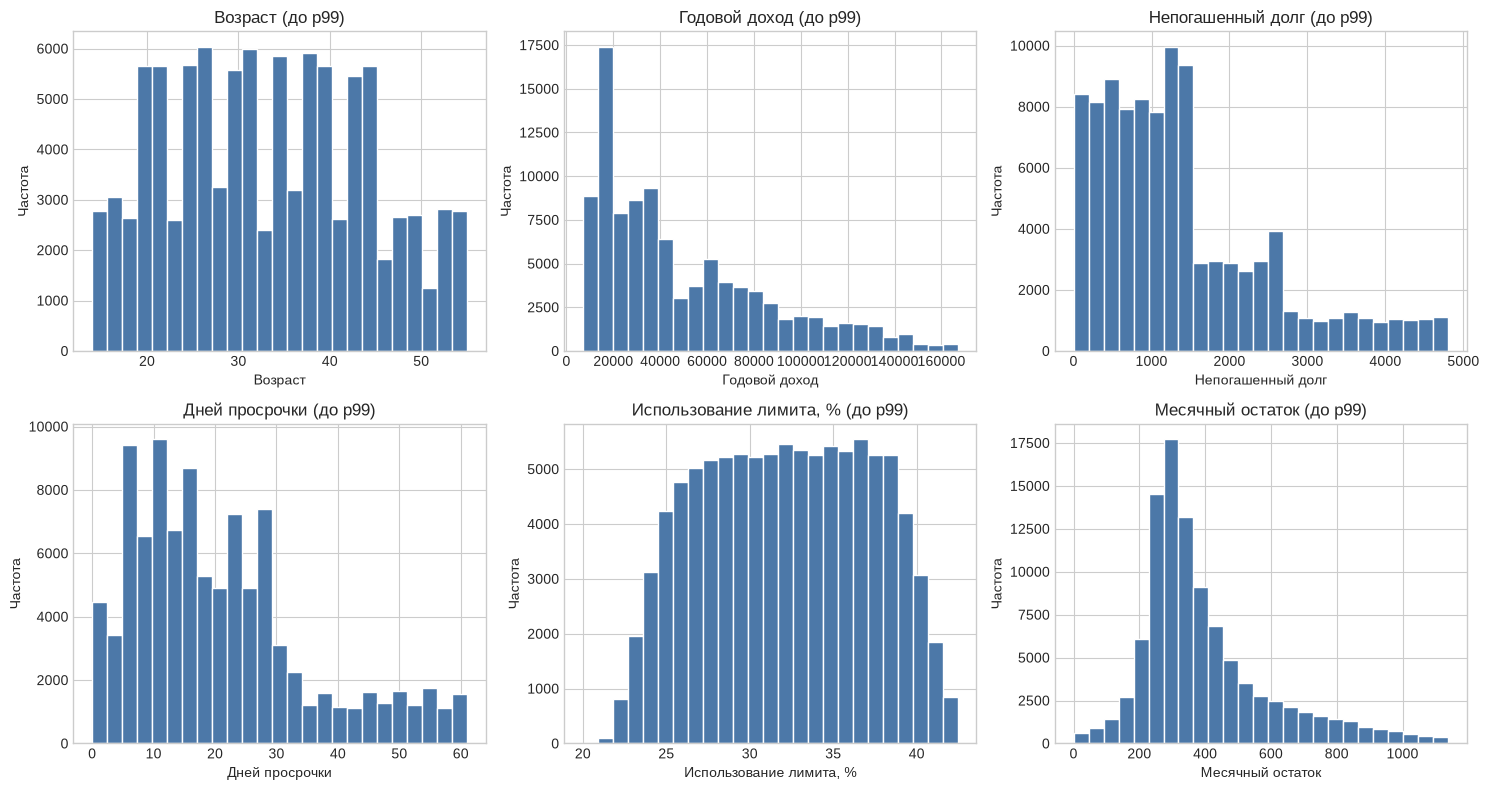

In [18]:
columns_to_plot = [
    ("Age", "Возраст"),
    ("Annual_Income", "Годовой доход"),
    ("Outstanding_Debt", "Непогашенный долг"),
    ("Delay_from_due_date", "Дней просрочки"),
    ("Credit_Utilization_Ratio", "Использование лимита, %"),
    ("Monthly_Balance", "Месячный остаток"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (column, title) in zip(axes.flat, columns_to_plot):
    values = train_clean[column]
    upper = values.quantile(0.99)
    ax.hist(values[values <= upper], bins=25, color="#4c78a8", edgecolor="white")
    ax.set_title(title + " (до p99)")
    ax.set_xlabel(title)
    ax.set_ylabel("Частота")
plt.tight_layout()
plt.show()

### 2.6. Наблюдения и рекомендации заказчику (сборщику данных)

**Что обнаружено при предобработке**

| Проблема | Пример | Масштаб (train) | Что сделано |
|---|---|---|---|
| Числа хранятся строками с мусорным `_` | `28_`, `34847.84_` | до 7% строк в 7 полях | удалён `_`, приведено к числу |
| Служебные маркеры вместо пропусков | `_______`, `_`, `!@9#%8`, `#F%$D@*&8` | 7–20% в 5 полях | заменены на `NaN` |
| Неявный пропуск `NM` | `Payment_of_Min_Amount` | 12% | оставлен отдельной категорией |
| Невозможные значения | возраст `-500` и `8698`, 1 798 счетов, ставка 5 797% | 1–3% | признаны пропусками, восстановлены по клиенту |
| Числовая заглушка | баланс $-3.3\cdot10^{26}$, инвестиции `10000` | ~4% | исключены |
| «Плавающие» стабильные признаки | возраст/доход/профессия меняются от месяца к месяцу | по многим клиентам | заменены модой клиента |
| Длительность истории строкой | `22 Years and 3 Months` | все строки | переведено в месяцы |

**Рекомендации сборщику данных**

1. **Валидация на входе.** Для числовых полей (возраст, число счетов/карт/кредитов, ставка) задать типы и допустимые диапазоны прямо в форме или в схеме БД; отклонять значения вне диапазона (например, возраст 14–100, ставка 0–50%).
2. **Единый маркер пропуска.** Вместо `_`, `_______`, `!@9#%8`, `NM` хранить `NULL` и отдельный флаг причины («не указано клиентом», «ошибка выгрузки»).
3. **Выпадающие списки вместо свободного ввода** для `Occupation`, `Credit_Mix`, `Payment_Behaviour`, `Payment_of_Min_Amount`, а для `Type_of_Loan` — множественный выбор из фиксированного справочника (сейчас 6 260 уникальных строк-комбинаций).
4. **Проверить функцию выгрузки/экспорта**: суффикс `_` у чисел и значение $-3.3\cdot10^{26}$ похожи на ошибку сериализации, а не на ручной ввод.
5. **Хранить стабильные атрибуты клиента в отдельной таблице** (возраст по дате рождения, профессия, доход с датой обновления), а не копировать их в каждую месячную запись — это устранит расхождения между месяцами.
6. **Кредитную историю хранить датой открытия первого кредита**, а длительность вычислять; так же задокументировать формулы `Changed_Credit_Limit` и `Credit_Utilization_Ratio`.
7. **Указать валюту и регион** в документации к набору.
8. Удалить или маскировать `Name` и `SSN` ещё на этапе выгрузки — для аналитики они не нужны и несут риск утечки персональных данных.

## 3. Первичная проверка гипотез

Лабораторная посвящена предобработке, поэтому ниже — только описательные сравнения. Они помогают убедиться, что очищенные признаки содержательно связаны с целью; полноценная проверка потребует статистических тестов и валидации модели.

In [19]:
score_order = ["Good", "Standard", "Poor"]
comparison = (
    train_clean.groupby("Credit_Score", observed=True)[
        ["Outstanding_Debt", "Delay_from_due_date", "Interest_Rate",
         "Num_Credit_Inquiries", "EMI_to_Monthly_Income"]
    ]
    .median()
    .reindex(score_order)
)
comparison.round(3)

,Outstanding_Debt,Delay_from_due_date,Interest_Rate,Num_Credit_Inquiries,EMI_to_Monthly_Income
Credit_Score,,,,,
Good,736.47,10.0,7.0,3.0,0.017
Standard,1001.61,18.0,13.0,5.0,0.023
Poor,1945.35,27.0,21.0,8.0,0.035


In [20]:
credit_mix_table = pd.crosstab(
    train_clean["Credit_Mix"], train_clean["Credit_Score"], normalize="index"
).mul(100).reindex(columns=score_order).round(1)
credit_mix_table

Credit_Score,Good,Standard,Poor
Credit_Mix,,,
Bad,1.5,38.4,60.1
Good,48.9,35.2,16.0
Standard,5.7,72.8,21.5


Описательные таблицы поддерживают основные гипотезы: при переходе от `Good` к `Poor` обычно растут долг, задержка, процентная ставка и число кредитных запросов; категория `Bad` имеет существенно большую долю `Poor`. Это ассоциации, а не доказательство причинного эффекта.

### 3.1. Сохранение результата

Сохраняем обе очищенные таблицы в `data/processed`. В `test` нет `Credit_Score`, остальные признаки совпадают с `train`.

In [21]:
processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)
train_output = processed_dir / "credit_score_train_clean.csv"
test_output = processed_dir / "credit_score_test_clean.csv"

train_clean.to_csv(train_output, index=False)
test_clean.to_csv(test_output, index=False)

print(f"Сохранено: {train_output.resolve()} ({train_output.stat().st_size / 1024**2:.1f} МБ)")
print(f"Сохранено: {test_output.resolve()} ({test_output.stat().st_size / 1024**2:.1f} МБ)")
display(train_clean.head())

Сохранено: /home/undndnwnkk/dev/university-works/data-analysis-3rd-course/eda-visualization/data/processed/credit_score_train_clean.csv (34.6 МБ)
Сохранено: /home/undndnwnkk/dev/university-works/data-analysis-3rd-course/eda-visualization/data/processed/credit_score_test_clean.csv (17.2 МБ)


,ID,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Month_Number,Credit_History_Months,Debt_to_Annual_Income,EMI_to_Monthly_Income,Investment_to_Monthly_Income,Age_Group,Delay_Band
0,0x1602,CUS_0xd40,January,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4,Good,809.98,26.822620,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good,1,265,0.042376,0.027167,0.044067,14–24,1–15 дней
1,0x1603,CUS_0xd40,February,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",0,6,11.27,4,Good,809.98,31.944960,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good,2,266,0.042376,0.027167,0.064817,14–24,без просрочки
2,0x1604,CUS_0xd40,March,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4,Good,809.98,28.609352,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good,3,267,0.042376,0.027167,0.044771,14–24,1–15 дней
3,0x1605,CUS_0xd40,April,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4,Good,809.98,31.377862,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good,4,268,0.042376,0.027167,0.109301,14–24,1–15 дней
4,0x1606,CUS_0xd40,May,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,6,11.27,4,Good,809.98,24.797347,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good,5,269,0.042376,0.027167,0.022698,14–24,1–15 дней


## Вывод

В работе подготовлены обучающая и тестовая части набора Credit Score Classification.

1. Исходная структура сохранена: 100 000 строк `train` и 50 000 строк `test`; строки не удалялись.
2. Исправлены числовые строки с `_`, технические категории и обычные пропуски; неявный пропуск `NM` сохранён отдельной категорией.
3. Невозможные значения признаны ошибками ввода, а не реальными выбросами: возраст в тысячи лет, сотни карт и счетов, огромные ставки и отрицательная числовая заглушка баланса исключены до заполнения.
4. Повторные месячные наблюдения использованы для восстановления стабильных характеристик клиента. Профили и статистики заполнения рассчитаны только на `train`, без целевой переменной.
5. Кредитная история переведена в месяцы с сохранением временной логики; для асимметричных месячных показателей использованы медианы.
6. `Name` и `SSN` удалены из-за приватности и отсутствия содержательной ценности. `ID` оставлен только как ключ и должен быть исключён перед обучением.
7. Добавлены интерпретируемые отношения нагрузки и категории возраста/просрочки. Итоговые таблицы не содержат пропусков и имеют одинаковый набор предикторов.

Сборщику данных даны рекомендации (раздел 2.6): валидация диапазонов, единый маркер пропуска, выпадающие списки, отдельная таблица стабильных атрибутов клиента.

Ограничение: границы аномалий заданы предметно и должны быть согласованы с владельцем данных перед промышленным применением. На следующем этапе следует построить пайплайн кодирования категорий, разделить данные **по клиентам**, а не по строкам, и сравнить модели с учётом дисбаланса классов.

# Лабораторная №2. Исследовательский анализ и визуализация данных

Используем таблицу `train_clean` из ЛР1: продолжаем с уже очищенными данными, не перечитывая файл. `test` для EDA не нужен – в нём нет целевой переменной.

**Цель ЛР2:** оценить, какие признаки связаны с `Credit_Score`, проверить гипотезы H1–H5 из ЛР1 и выделить кандидатов в топ-5 факторов для модели в ЛР3.

| № | Гипотеза |
|---|---|
| H1 | Больший долг и более длительные просрочки связаны с худшим `Credit_Score` |
| H2 | Высокая процентная ставка чаще встречается у клиентов с рейтингом `Poor` |
| H3 | Категория `Credit_Mix = Bad` связана с худшим рейтингом |
| H4 | Частые кредитные запросы связаны с ухудшением рейтинга |
| H5 | Большая доля EMI-платежей в месячном доходе связана с худшим рейтингом |

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

BASE_COLOR = "#4c78a8"
ACCENT_COLOR = "#f58518"
SCORE_ORDER = ["Good", "Standard", "Poor"]
SCORE_COLORS = {"Good": "#4c956c", "Standard": "#4c78a8", "Poor": "#d1495b"}
SCORE_PALETTE = [SCORE_COLORS[s] for s in SCORE_ORDER]
SCORE_RU = {"Good": "Good (хороший)", "Standard": "Standard (средний)", "Poor": "Poor (плохой)"}

LABELS = {
    "Age": "Возраст, лет",
    "Annual_Income": "Годовой доход, у.е.",
    "Monthly_Inhand_Salary": "Месячный доход на руки, у.е.",
    "Num_Bank_Accounts": "Число банковских счетов, шт.",
    "Num_Credit_Card": "Число кредитных карт, шт.",
    "Interest_Rate": "Процентная ставка, %",
    "Num_of_Loan": "Число кредитов, шт.",
    "Delay_from_due_date": "Просрочка платежа, дней",
    "Num_of_Delayed_Payment": "Число просроченных платежей, шт.",
    "Changed_Credit_Limit": "Изменение кредитного лимита, %",
    "Num_Credit_Inquiries": "Число кредитных запросов, шт.",
    "Outstanding_Debt": "Непогашенный долг, у.е.",
    "Credit_Utilization_Ratio": "Использование лимита, %",
    "Total_EMI_per_month": "Ежемесячный платёж EMI, у.е.",
    "Amount_invested_monthly": "Инвестиции в месяц, у.е.",
    "Monthly_Balance": "Остаток на конец месяца, у.е.",
    "Credit_History_Months": "Длительность кредитной истории, мес.",
    "Debt_to_Annual_Income": "Долг / годовой доход, доля",
    "EMI_to_Monthly_Income": "EMI / месячный доход, доля",
    "Investment_to_Monthly_Income": "Инвестиции / месячный доход, доля",
    "Credit_Score": "Кредитный рейтинг",
}

def label(column):
    return LABELS.get(column, column)

df = train_clean.copy()
df["Credit_Score"] = pd.Categorical(df["Credit_Score"], categories=SCORE_ORDER, ordered=True)
# Порядковая кодировка цели для ранговых корреляций: чем больше, тем лучше рейтинг.
df["Score_Rank"] = df["Credit_Score"].map({"Poor": 0, "Standard": 1, "Good": 2}).astype(int)

NUMERIC = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card",
    "Interest_Rate", "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
    "Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Total_EMI_per_month", "Amount_invested_monthly",
    "Monthly_Balance", "Credit_History_Months", "Debt_to_Annual_Income",
    "EMI_to_Monthly_Income", "Investment_to_Monthly_Income",
]
CATEGORICAL = ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("Размер:", df.shape, "| клиентов:", df["Customer_ID"].nunique())

Размер: (100000, 33) | клиентов: 12500


Один клиент встречается 8 раз (январь–август), а стабильные признаки в ЛР1 восстановлены одинаковыми для всех его месяцев. Если подать в тест все 100 000 строк, один клиент будет учтён 8 раз и p-значения окажутся заниженными.

Поэтому графики распределений строим по всем строкам, а тесты нормальности, корреляции и гипотез считаем на срезе `snapshot` – одна строка на клиента, **август**: 12 500 независимых наблюдений.

In [23]:
snapshot = df[df["Month_Number"] == 8].copy()
print("Срез (август):", snapshot.shape, "| уникальных клиентов:", snapshot["Customer_ID"].nunique())
snapshot["Credit_Score"].value_counts(normalize=True).reindex(SCORE_ORDER).mul(100).round(2).to_frame("доля, %")

Срез (август): (12500, 33) | уникальных клиентов: 12500


,"доля, %"
Credit_Score,
Good,19.300
Standard,51.880
Poor,28.820


## 1. Изучение распределений признаков

### 1.1. Гистограммы

#### Основные характеристики

In [24]:
descriptive = df[NUMERIC].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T
descriptive = descriptive.rename(columns={
    "count": "Наблюдений", "mean": "Среднее", "median": "Медиана",
    "std": "Станд. отклонение", "min": "Минимум", "max": "Максимум", "skew": "Асимметрия",
})
descriptive.round(3)

,Наблюдений,Среднее,Медиана,Станд. отклонение,Минимум,Максимум,Асимметрия
Age,"100,000.000",33.310,33.000,10.765,14.000,56.000,0.157
Annual_Income,"100,000.000","50,505.123","36,999.705","38,299.422","7,005.930","179,987.280",1.130
Monthly_Inhand_Salary,"100,000.000","4,198.390","3,094.825","3,187.570",303.645,"15,204.633",1.129
Num_Bank_Accounts,"100,000.000",5.369,5.000,2.593,0.000,10.000,-0.189
Num_Credit_Card,"100,000.000",5.534,5.000,2.067,0.000,11.000,0.226
Interest_Rate,"100,000.000",14.532,13.000,8.741,1.000,34.000,0.496
Num_of_Loan,"100,000.000",3.533,3.000,2.446,0.000,9.000,0.446
Delay_from_due_date,"100,000.000",21.082,18.000,14.840,0.000,67.000,0.974
Num_of_Delayed_Payment,"100,000.000",13.339,14.000,6.305,0.000,98.000,-0.055
Changed_Credit_Limit,"100,000.000",10.389,9.400,6.783,-6.490,36.970,0.642


#### Распределения на гистограммах

Для признаков с очень длинным правым хвостом (`Total_EMI_per_month`) ось X ограничена 99-м перцентилем, чтобы была видна основная масса; сам хвост разобран в разделе 1.3.

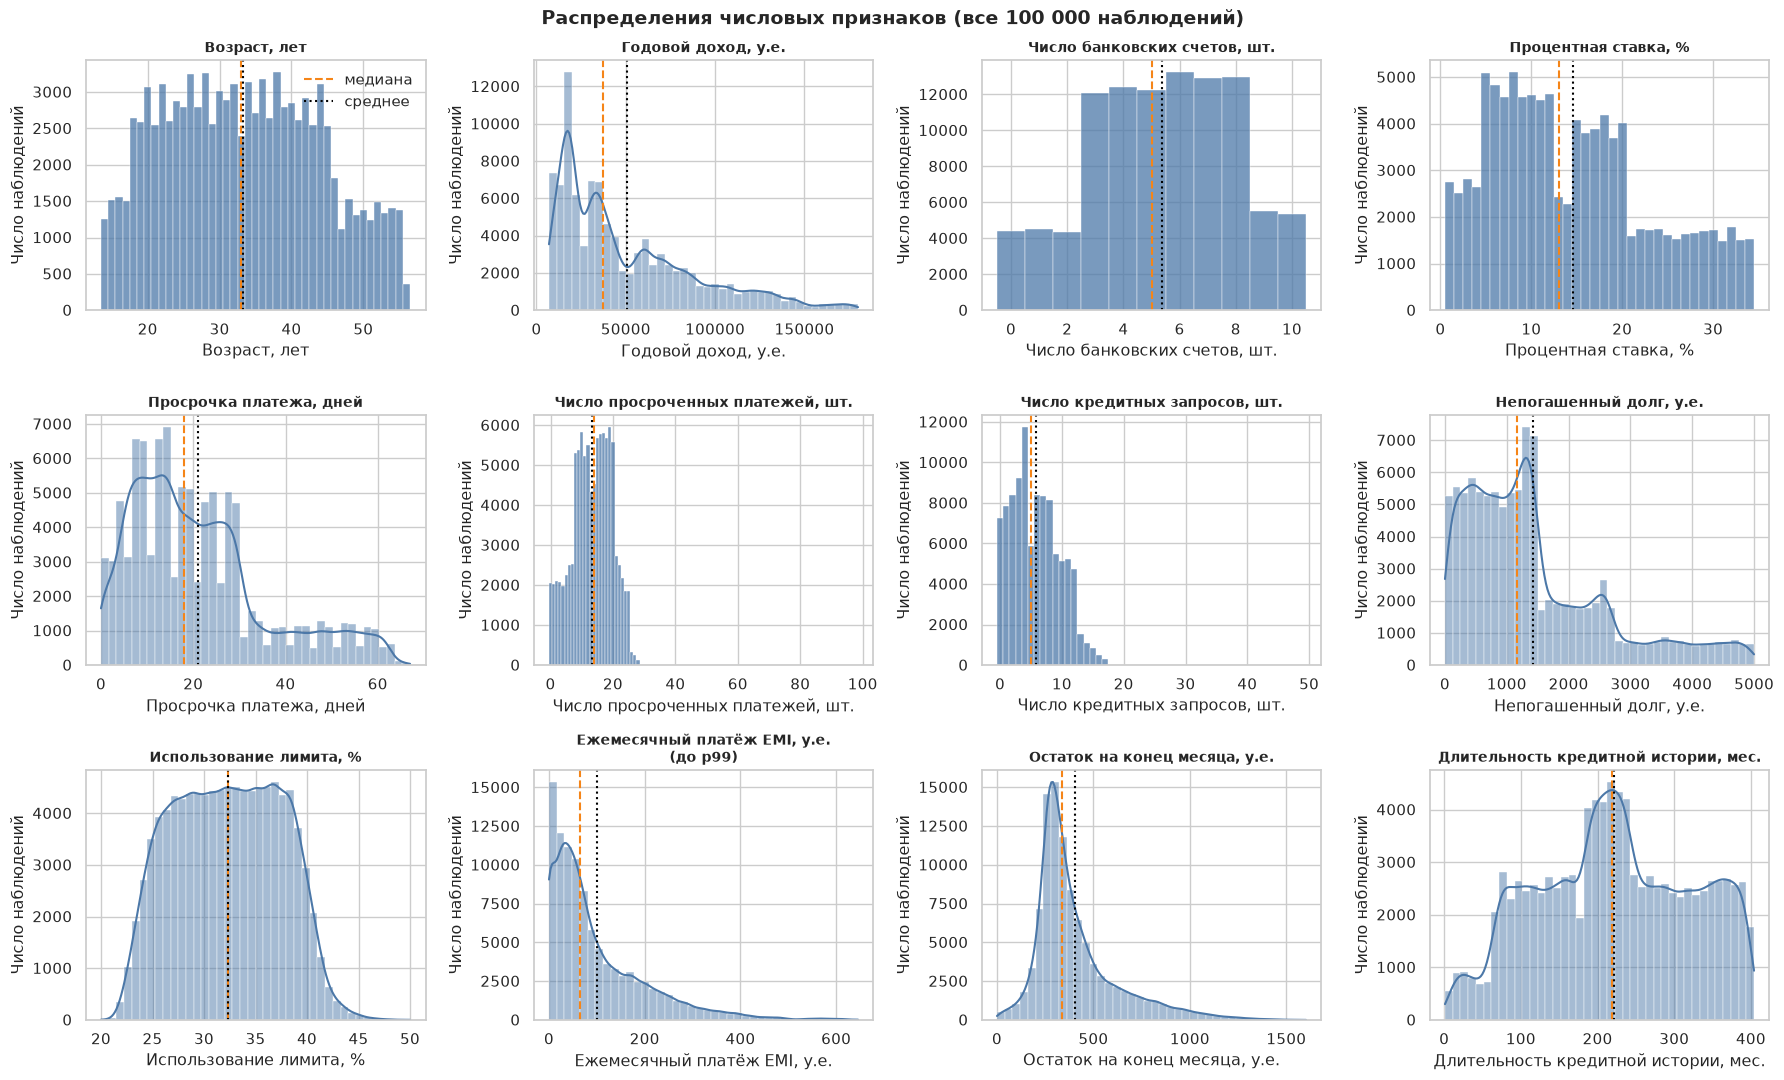

In [25]:
HIST_FEATURES = [
    "Age", "Annual_Income", "Num_Bank_Accounts", "Interest_Rate",
    "Delay_from_due_date", "Num_of_Delayed_Payment", "Num_Credit_Inquiries", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Total_EMI_per_month", "Monthly_Balance", "Credit_History_Months",
]
CLIP_AT_P99 = {"Total_EMI_per_month", "EMI_to_Monthly_Income", "Amount_invested_monthly"}

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, column in zip(axes.flat, HIST_FEATURES):
    values = df[column]
    title = label(column)
    if column in CLIP_AT_P99:
        values = values[values <= values.quantile(0.99)]
        title += "\n(до p99)"
    discrete = df[column].dtype.kind == "i" and df[column].nunique() <= 60
    sns.histplot(values, ax=ax, color=BASE_COLOR, kde=not discrete, discrete=discrete,
                 bins="auto" if discrete else 40, edgecolor="white", linewidth=0.3)
    ax.axvline(values.median(), color=ACCENT_COLOR, linestyle="--", linewidth=1.5, label="медиана")
    ax.axvline(values.mean(), color="black", linestyle=":", linewidth=1.5, label="среднее")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(label(column))
    ax.set_ylabel("Число наблюдений")
axes.flat[0].legend(loc="upper right")
fig.suptitle("Распределения числовых признаков (все 100 000 наблюдений)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Возраст, использование лимита и длительность кредитной истории распределены почти равномерно, без выраженного пика. Денежные признаки и доли имеют длинный правый хвост: среднее долга – 1 426 у.е., медиана – 1 166 у.е.; у ежемесячного платежа EMI среднее 117 у.е. при медиане 66 у.е. (асимметрия ≈ 27). Поэтому для сравнения классов дальше используем медианы.

### 1.2. Проверка нормальности распределений

Используем три инструмента:
1. **Асимметрия (skewness)** и **эксцесс (excess kurtosis)**: для нормального распределения оба равны 0. Ориентир: |skew| < 0.5 — почти симметрично, 0.5–1 — умеренная асимметрия, > 1 — сильная.
2. **Тест Д'Агостино–Пирсона** (`scipy.stats.normaltest`), H₀: распределение нормальное. Тест Шапиро–Уилка не используем: при n > 5 000 его p-значение неточно.
3. **Q-Q-графики** — визуальная проверка, потому что при n = 12 500 любой тест отвергнет нормальность даже при малом отклонении.

In [26]:
normality = []
for column in NUMERIC:
    values = snapshot[column]
    k2, p_value = stats.normaltest(values)
    skew = values.skew()
    normality.append({
        "признак": column,
        "среднее": values.mean(),
        "медиана": values.median(),
        "асимметрия": skew,
        "эксцесс": values.kurt(),
        "K² Д'Агостино": k2,
        "p-value": p_value,
        "нормально (α=0.05)": "да" if p_value > 0.05 else "нет",
        "форма": ("≈ симметричное" if abs(skew) < 0.5
                  else "умеренная правая асимм." if 0.5 <= skew < 1
                  else "сильная правая асимм." if skew >= 1
                  else "левая асимметрия"),
    })
normality = pd.DataFrame(normality).set_index("признак")
normality.style.format({
    "среднее": "{:,.2f}", "медиана": "{:,.2f}", "асимметрия": "{:.2f}", "эксцесс": "{:.2f}",
    "K² Д'Агостино": "{:,.1f}", "p-value": "{:.1e}",
}).background_gradient(subset=["асимметрия"], cmap="RdBu_r", vmin=-3, vmax=3)

,среднее,медиана,асимметрия,эксцесс,K² Д'Агостино,p-value,нормально (α=0.05),форма
признак,,,,,,,,
Age,33.31,33.00,0.16,-0.93,"2,003.6",0.0e+00,нет,≈ симметричное
Annual_Income,"50,505.12","36,999.71",1.13,0.61,"1,889.1",0.0e+00,нет,сильная правая асимм.
Monthly_Inhand_Salary,"4,198.39","3,094.83",1.13,0.62,"1,890.5",0.0e+00,нет,сильная правая асимм.
Num_Bank_Accounts,5.37,5.00,-0.19,-0.69,712.4,2.0e-155,нет,≈ симметричное
Num_Credit_Card,5.53,5.00,0.23,-0.33,183.8,1.2e-40,нет,≈ симметричное
Interest_Rate,14.53,13.00,0.50,-0.68,"1,064.4",7.3e-232,нет,≈ симметричное
Num_of_Loan,3.53,3.00,0.45,-0.61,812.9,3.0e-177,нет,≈ симметричное
Delay_from_due_date,21.08,18.00,0.98,0.36,"1,475.7",0.0e+00,нет,умеренная правая асимм.
Num_of_Delayed_Payment,13.34,14.00,-0.04,0.90,212.3,7.9e-47,нет,≈ симметричное


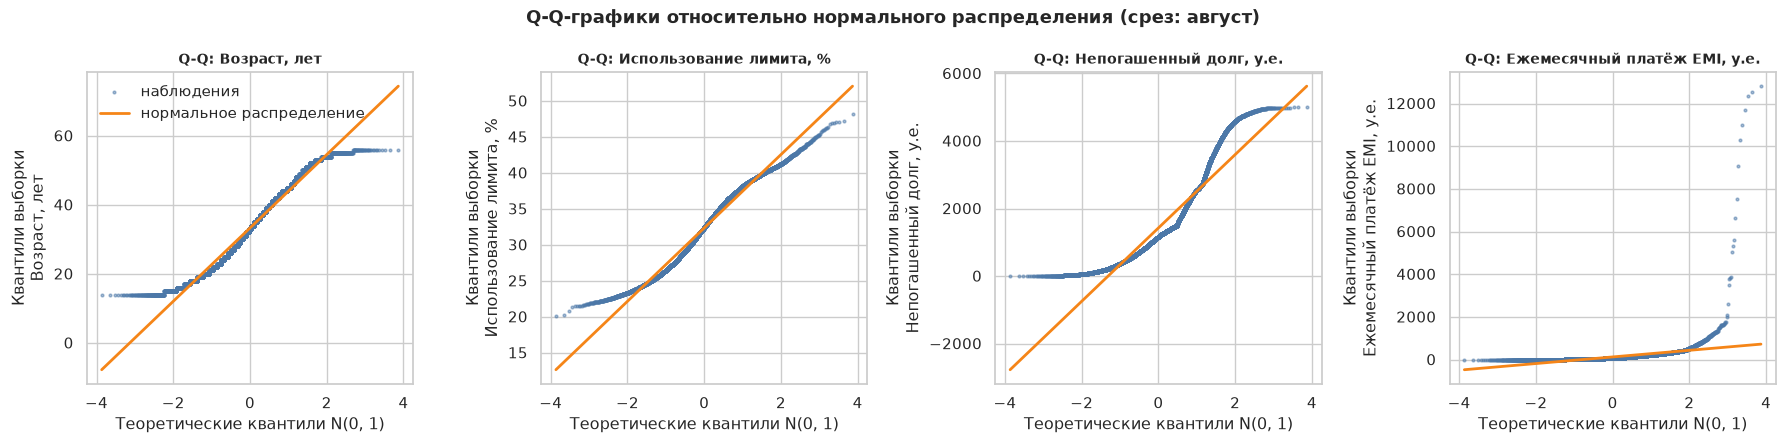

In [27]:
QQ_FEATURES = ["Age", "Credit_Utilization_Ratio", "Outstanding_Debt", "Total_EMI_per_month"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, column in zip(axes, QQ_FEATURES):
    (theoretical, ordered), (slope, intercept, _) = stats.probplot(snapshot[column], dist="norm")
    ax.scatter(theoretical, ordered, s=4, color=BASE_COLOR, alpha=0.5, label="наблюдения")
    ax.plot(theoretical, slope * theoretical + intercept, color=ACCENT_COLOR, linewidth=2,
            label="нормальное распределение")
    ax.set_title(f"Q-Q: {label(column)}", fontsize=10)
    ax.set_xlabel("Теоретические квантили N(0, 1)")
    ax.set_ylabel(f"Квантили выборки\n{label(column)}")
axes[0].legend(loc="upper left")
fig.suptitle("Q-Q-графики относительно нормального распределения (срез: август)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

#### Логарифмирование правоасимметричных признаков

Денежные величины обычно близки к логнормальному распределению. Проверим, насколько `log1p` уменьшает асимметрию — это пригодится для линейных моделей в ЛР3.

,асимметрия исходная,асимметрия после log1p
Annual_Income,1.130,-0.080
Outstanding_Debt,1.210,-1.310
Total_EMI_per_month,24.440,-1.160
Amount_invested_monthly,2.630,-0.170
Monthly_Balance,1.550,-0.970
Debt_to_Annual_Income,2.850,2.470


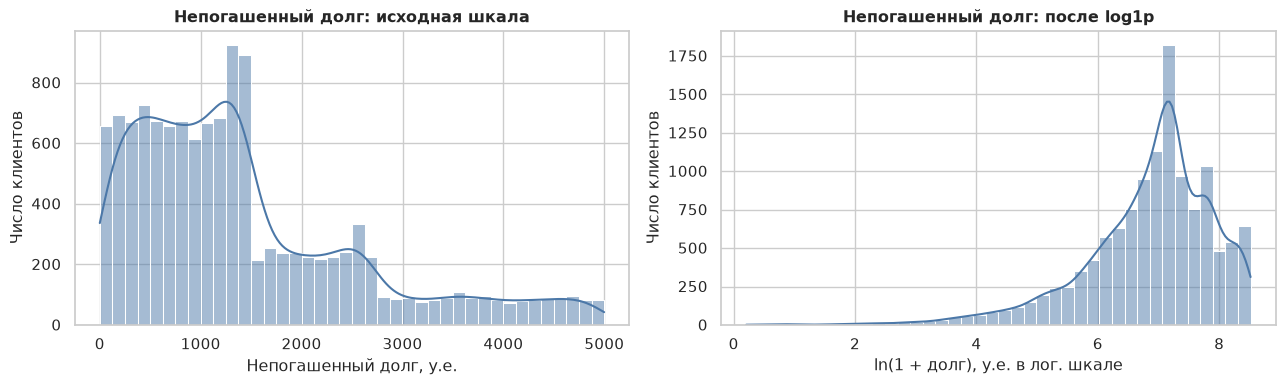

In [28]:
LOG_FEATURES = ["Annual_Income", "Outstanding_Debt", "Total_EMI_per_month",
                "Amount_invested_monthly", "Monthly_Balance", "Debt_to_Annual_Income"]
log_table = pd.DataFrame({
    "асимметрия исходная": snapshot[LOG_FEATURES].skew(),
    "асимметрия после log1p": np.log1p(snapshot[LOG_FEATURES]).skew(),
})
display(log_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(snapshot["Outstanding_Debt"], ax=axes[0], color=BASE_COLOR, kde=True, bins=40)
axes[0].set_title("Непогашенный долг: исходная шкала")
axes[0].set_xlabel(label("Outstanding_Debt"))
axes[0].set_ylabel("Число клиентов")
sns.histplot(np.log1p(snapshot["Outstanding_Debt"]), ax=axes[1], color=BASE_COLOR, kde=True, bins=40)
axes[1].set_title("Непогашенный долг: после log1p")
axes[1].set_xlabel("ln(1 + долг), у.е. в лог. шкале")
axes[1].set_ylabel("Число клиентов")
plt.tight_layout()
plt.show()

- **Ни один признак не распределён нормально** (все p < 10⁻¹⁰). Это ожидаемо для финансовых данных и означает, что для сравнения групп нужны **непараметрические** методы (Краскел–Уоллис, ранговая корреляция Спирмена), а для описания — медиана и квартили, а не среднее и σ.
- **Почти равномерные / платообразные** (|skew| < 0.3, эксцесс ≈ −0.9): `Age` (18–56 лет), `Credit_Utilization_Ratio` (20–50%), `Credit_History_Months`, `Num_Bank_Accounts`. Отрицательный эксцесс = «плоская» вершина без выраженного пика; Q-Q-график имеет S-образную форму.
- **Умеренная правая асимметрия** (0.4–1.0): `Interest_Rate`, `Num_of_Loan`, `Num_Credit_Inquiries`, `Delay_from_due_date`, `Changed_Credit_Limit` — большинство клиентов с невысокими значениями и «хвост» в сторону больших.
- **Сильная правая асимметрия** (> 1): денежные признаки `Annual_Income`, `Outstanding_Debt`, `Monthly_Balance`, `Amount_invested_monthly` и отношения `Debt_to_Annual_Income`, `EMI_to_Monthly_Income`. Среднее заметно больше медианы.
- **Экстремальный хвост**: `Total_EMI_per_month` (асимметрия ≈ 24, эксцесс ≈ 780) — основная масса до ~400 у.е., но отдельные значения до 16 000 у.е.
- `log1p` хорошо симметризует доход и инвестиции (асимметрия 1.1 → −0.1 и 2.6 → −0.2), но для долга, EMI и остатка **перекорректирует** — появляется левая асимметрия (−1.0…−1.3) из-за массы значений около нуля. Значит, логарифм — не универсальное решение: для линейной модели в ЛР3 лучше использовать устойчивое к форме распределения преобразование (например, квантильное или `PowerTransformer` Йео–Джонсона), а для деревьев преобразование не нужно.
- У многих признаков видны **ступеньки и плато** (ставка: провалы около 13% и 17%; долг: резкий спад после ~1 500 и ~2 700 у.е.; число счетов: почти равномерно на 3–8). Для реальных данных это нетипично и подтверждает синтетическое происхождение набора, отмеченное в ЛР1.
- `Num_of_Delayed_Payment` выглядит близким к симметричному (skew ≈ 0), но имеет единичные значения до 98 при медиане 14 — см. выбросы.

### 1.3. Оставшиеся выбросы

В ЛР1 удалены только **невозможные** значения (возраст −500, ставка 5 797%). Теперь ищем **статистические** выбросы правилом Тьюки: значение вне $[Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR]$. Это не автоматически ошибка: для асимметричного распределения правило «срабатывает» на естественный длинный хвост.

In [29]:
q1 = df[NUMERIC].quantile(0.25)
q3 = df[NUMERIC].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (df[NUMERIC] < lower) | (df[NUMERIC] > upper)

outliers = pd.DataFrame({
    "Q1": q1, "медиана": df[NUMERIC].median(), "Q3": q3,
    "верхняя граница": upper, "max": df[NUMERIC].max(),
    "выбросов, шт.": is_outlier.sum(),
    "выбросов, %": is_outlier.mean().mul(100),
}).sort_values("выбросов, %", ascending=False)
outliers[outliers["выбросов, шт."] > 0].style.format({
    "Q1": "{:,.2f}", "медиана": "{:,.2f}", "Q3": "{:,.2f}", "верхняя граница": "{:,.2f}",
    "max": "{:,.2f}", "выбросов, шт.": "{:,.0f}", "выбросов, %": "{:.2f}",
}).bar(subset=["выбросов, %"], color="#f2b6b6")

,Q1,медиана,Q3,верхняя граница,max,"выбросов, шт.","выбросов, %"
Debt_to_Annual_Income,0.01,0.03,0.07,0.16,0.68,"10,496",10.50
Amount_invested_monthly,73.73,129.36,234.35,475.27,"1,977.33","8,201",8.20
Monthly_Balance,270.32,337.27,471.93,774.34,"1,602.04","7,657",7.66
Outstanding_Debt,566.07,"1,166.15","1,945.96","4,015.80","4,998.07","5,272",5.27
Total_EMI_per_month,29.27,66.50,147.68,325.30,"16,305.00","5,115",5.12
Delay_from_due_date,10.00,18.00,28.00,55.00,67.00,"4,002",4.00
EMI_to_Monthly_Income,0.01,0.02,0.04,0.08,1.48,"3,513",3.51
Monthly_Inhand_Salary,"1,626.72","3,094.83","5,961.66","12,464.08","15,204.63","2,008",2.01
Annual_Income,"19,342.97","36,999.71","71,683.47","150,194.22","179,987.28","2,000",2.00
Num_Credit_Inquiries,3.00,5.00,8.00,15.50,49.00,786,0.79


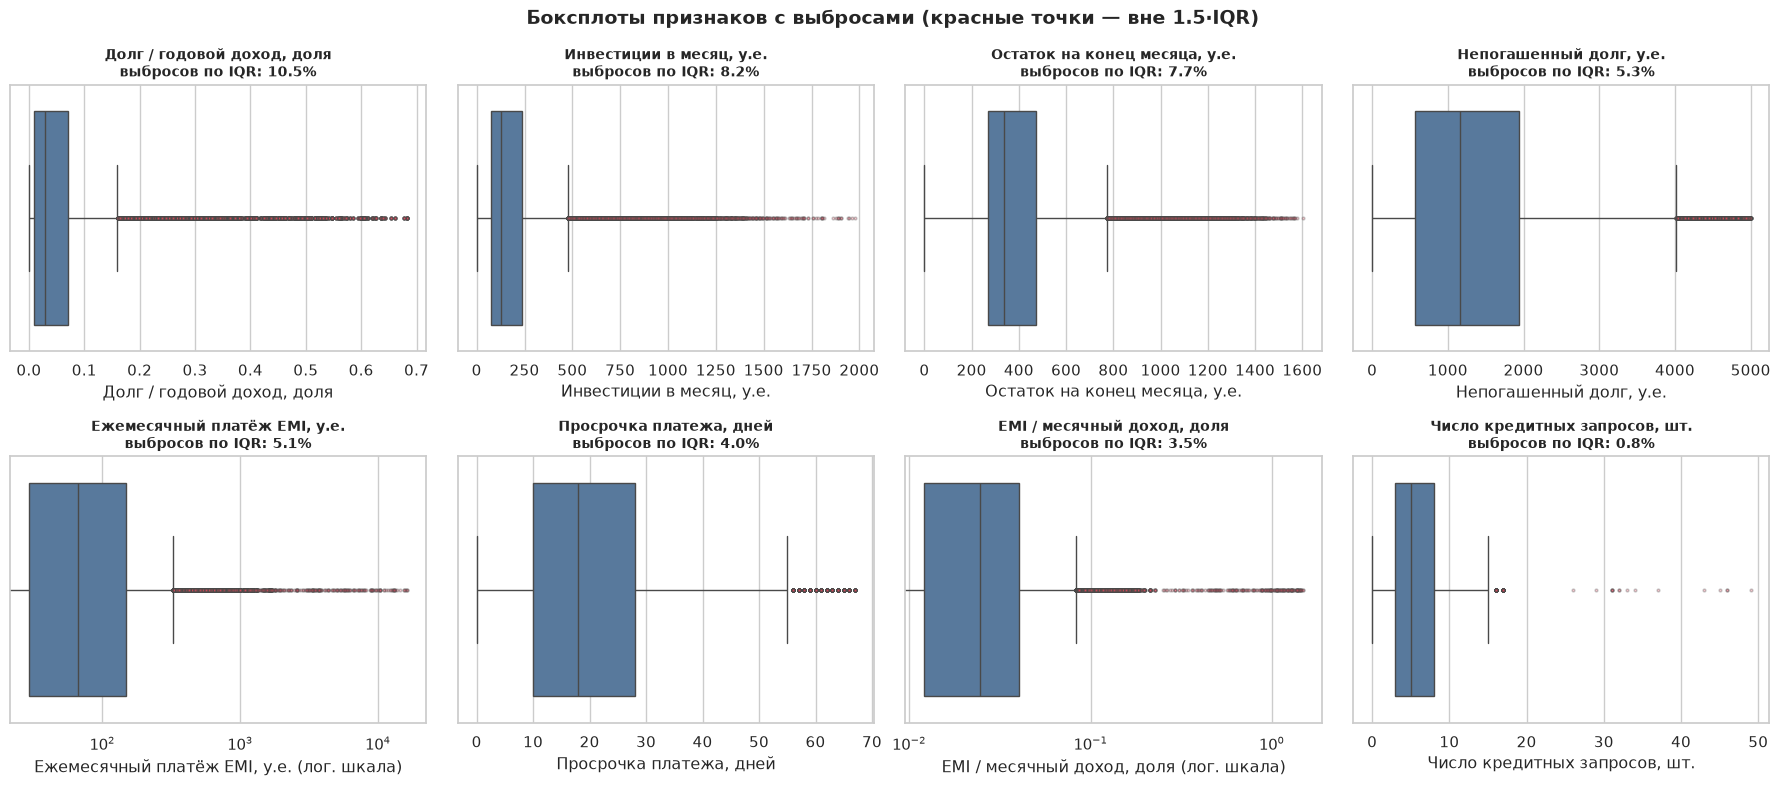

In [30]:
OUTLIER_FEATURES = ["Debt_to_Annual_Income", "Amount_invested_monthly", "Monthly_Balance",
                    "Outstanding_Debt", "Total_EMI_per_month", "Delay_from_due_date",
                    "EMI_to_Monthly_Income", "Num_Credit_Inquiries"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, column in zip(axes.flat, OUTLIER_FEATURES):
    sns.boxplot(x=df[column], ax=ax, color=BASE_COLOR, fliersize=2,
                flierprops={"marker": "o", "markerfacecolor": "#d1495b", "alpha": 0.3})
    ax.set_title(f"{label(column)}\nвыбросов по IQR: {is_outlier[column].mean():.1%}", fontsize=10)
    ax.set_xlabel(label(column))
    if column in {"Total_EMI_per_month", "EMI_to_Monthly_Income"}:
        ax.set_xscale("log")
        ax.set_xlabel(label(column) + " (лог. шкала)")
fig.suptitle("Боксплоты признаков с выбросами (красные точки — вне 1.5·IQR)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [31]:
# Детальнее про самые подозрительные хвосты.
emi_over_income = df["EMI_to_Monthly_Income"] > 1
print(f"EMI больше месячного дохода: {emi_over_income.sum()} строк "
      f"({emi_over_income.mean():.2%}), клиентов: {df.loc[emi_over_income, 'Customer_ID'].nunique()}")
print(f"EMI > 2000 у.е.: {(df['Total_EMI_per_month'] > 2000).sum()} строк; "
      f"медиана EMI = {df['Total_EMI_per_month'].median():.1f} у.е.")
print(f"Просроченных платежей > 30: {(df['Num_of_Delayed_Payment'] > 30).sum()} строк")
print(f"Кредитных запросов > 20: {(df['Num_Credit_Inquiries'] > 20).sum()} строк")

print("\nДоля Poor среди выбросов и остальных:")
for column in ["Outstanding_Debt", "Delay_from_due_date", "Debt_to_Annual_Income", "Total_EMI_per_month"]:
    poor_out = (df.loc[is_outlier[column], "Credit_Score"] == "Poor").mean()
    poor_in = (df.loc[~is_outlier[column], "Credit_Score"] == "Poor").mean()
    print(f"  {column:<24} выбросы: {poor_out:6.1%}   остальные: {poor_in:6.1%}")

EMI больше месячного дохода: 79 строк (0.08%), клиентов: 79
EMI > 2000 у.е.: 158 строк; медиана EMI = 66.5 у.е.
Просроченных платежей > 30: 12 строк
Кредитных запросов > 20: 16 строк

Доля Poor среди выбросов и остальных:
  Outstanding_Debt         выбросы:  47.5%   остальные:  28.0%
  Delay_from_due_date      выбросы:  65.5%   остальные:  27.5%
  Debt_to_Annual_Income    выбросы:  55.7%   остальные:  25.9%
  Total_EMI_per_month      выбросы:  26.2%   остальные:  29.1%


- **Денежные признаки и доли** (`Debt_to_Annual_Income`, `Amount_invested_monthly`, `Monthly_Balance`, `Outstanding_Debt`; 5–10% «выбросов»): это естественный правый хвост логнормального распределения, а не ошибки — значения правдоподобны (долг до 5 000 у.е., остаток до 1 600 у.е.). **Решение: оставляем.** Удаление 5–10% выборки выбросило бы именно самых закредитованных клиентов — а среди выбросов по долгу и просрочке доля `Poor` заметно выше, т.е. это информативные наблюдения.
- **`Total_EMI_per_month`** (5%): большинство «выбросов» — умеренные значения 300–1 000 у.е., но есть единичные значения на порядок выше медианы (до 16 000 у.е.). Строки, где EMI превышает месячный доход, сомнительны: по смыслу человек не может долго платить больше, чем получает. Таких строк мало (см. вывод выше); **оставляем, но помечаем как подозрительные для заказчика**, а в модели используем деревья (нечувствительны к масштабу) и логарифм для линейной модели.
- **`Delay_from_due_date`** (4%): просрочки 55–67 дней — реальное поведение должников. Оставляем.
- **`Num_of_Delayed_Payment` и `Num_Credit_Inquiries`**: единичные значения > 30 и > 20 при медианах 14 и 5 — вероятно, остатки ошибок ввода, не попавшие под границы ЛР1. Их доля < 1%, на ранговые методы они почти не влияют. Оставляем.
- Итог: **оставшиеся выбросы не удаляем**; используем устойчивые методы — медианы, ранговую корреляцию Спирмена, критерий Краскела–Уоллиса, а в ЛР3 — деревья и `log1p` для линейной модели.

## 2. Корреляционный анализ

### 2.1. Корреляционная матрица

#### Расчёт связей

Используем **коэффициент Спирмена** (ρ), а не Пирсона, потому что: (1) распределения ненормальны и асимметричны; (2) есть выбросы, к которым Пирсон чувствителен; (3) цель `Credit_Score` порядковая (`Poor` < `Standard` < `Good`), и мы кодируем её как `Score_Rank` = 0/1/2. Спирмен измеряет **монотонную** связь, не обязательно линейную.

Матрица считается на срезе (август), чтобы не учитывать клиента 8 раз.

In [32]:
corr = snapshot[NUMERIC + ["Score_Rank"]].corr(method="spearman")
# Маска верхнего треугольника: каждая пара признаков учитывается один раз.
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
corr.round(2)

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,Credit_History_Months,Debt_to_Annual_Income,EMI_to_Monthly_Income,Investment_to_Monthly_Income,Score_Rank
Age,1.000,0.080,0.080,-0.180,-0.130,-0.200,-0.200,-0.160,-0.170,-0.150,-0.230,-0.200,0.010,-0.080,0.050,0.110,0.220,-0.170,-0.170,-0.030,0.130
Annual_Income,0.080,1.000,0.990,-0.270,-0.210,-0.300,-0.250,-0.240,-0.260,-0.160,-0.270,-0.280,0.140,0.490,0.650,0.600,0.270,-0.730,-0.210,-0.320,0.190
Monthly_Inhand_Salary,0.080,0.990,1.000,-0.270,-0.200,-0.290,-0.250,-0.240,-0.260,-0.160,-0.270,-0.270,0.140,0.480,0.650,0.610,0.270,-0.720,-0.220,-0.320,0.190
Num_Bank_Accounts,-0.180,-0.270,-0.270,1.000,0.430,0.590,0.460,0.570,0.590,0.300,0.510,0.500,-0.070,0.110,-0.180,-0.310,-0.490,0.470,0.380,0.080,-0.340
Num_Credit_Card,-0.130,-0.210,-0.200,0.430,1.000,0.470,0.380,0.440,0.400,0.200,0.420,0.460,-0.050,0.110,-0.140,-0.250,-0.400,0.410,0.320,0.060,-0.340
Interest_Rate,-0.200,-0.300,-0.290,0.590,0.470,1.000,0.530,0.570,0.580,0.340,0.610,0.610,-0.070,0.140,-0.200,-0.350,-0.580,0.560,0.440,0.090,-0.420
Num_of_Loan,-0.200,-0.250,-0.250,0.460,0.380,0.530,1.000,0.450,0.460,0.310,0.550,0.560,-0.080,0.550,-0.170,-0.480,-0.600,0.500,0.840,0.070,-0.320
Delay_from_due_date,-0.160,-0.240,-0.240,0.570,0.440,0.570,0.450,1.000,0.550,0.270,0.510,0.520,-0.050,0.140,-0.160,-0.300,-0.480,0.470,0.380,0.070,-0.380
Num_of_Delayed_Payment,-0.170,-0.260,-0.260,0.590,0.400,0.580,0.460,0.550,1.000,0.290,0.490,0.480,-0.070,0.120,-0.180,-0.310,-0.490,0.460,0.380,0.080,-0.310
Changed_Credit_Limit,-0.150,-0.160,-0.160,0.300,0.200,0.340,0.310,0.270,0.290,1.000,0.350,0.320,-0.020,0.100,-0.110,-0.190,-0.390,0.300,0.270,0.040,-0.140


#### Признаки, сильнее всего связанные с рейтингом

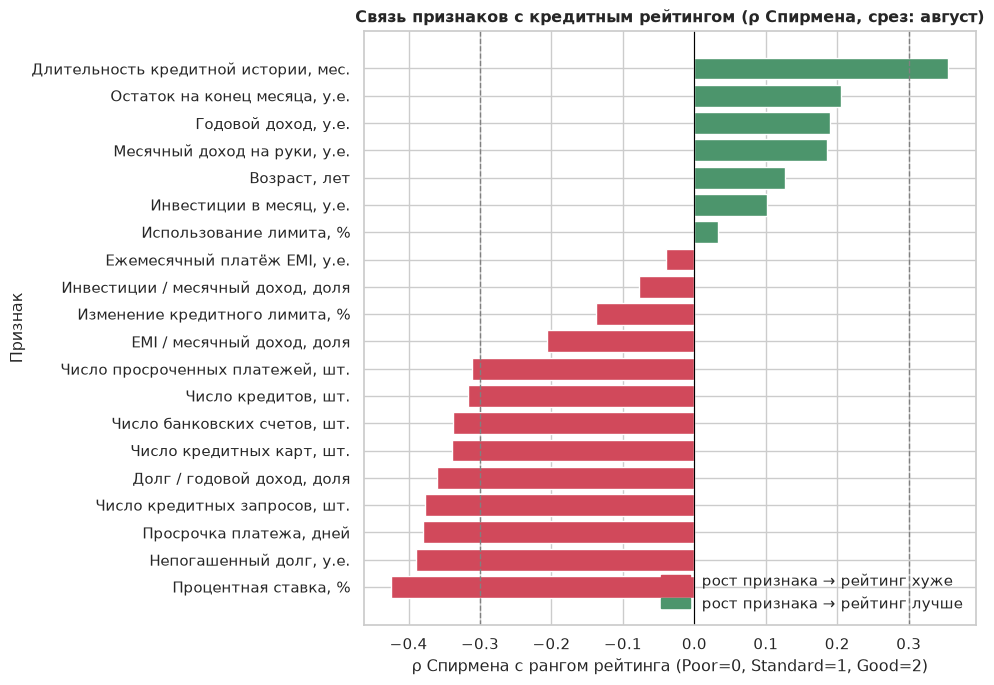

,ρ с рейтингом
Interest_Rate,-0.424
Outstanding_Debt,-0.389
Delay_from_due_date,-0.380
Num_Credit_Inquiries,-0.378
Debt_to_Annual_Income,-0.360
Credit_History_Months,0.355
Num_Credit_Card,-0.339
Num_Bank_Accounts,-0.338
Num_of_Loan,-0.317
Num_of_Delayed_Payment,-0.312


In [33]:
target_corr = corr["Score_Rank"].drop("Score_Rank").sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
colors = [SCORE_COLORS["Poor"] if v < 0 else SCORE_COLORS["Good"] for v in target_corr]
ax.barh([label(c) for c in target_corr.index], target_corr.values, color=colors)
for threshold in (-0.3, 0.3):
    ax.axvline(threshold, color="grey", linestyle="--", linewidth=1)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Связь признаков с кредитным рейтингом (ρ Спирмена, срез: август)")
ax.set_xlabel("ρ Спирмена с рангом рейтинга (Poor=0, Standard=1, Good=2)")
ax.set_ylabel("Признак")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SCORE_COLORS["Poor"], label="рост признака → рейтинг хуже"),
                   Patch(color=SCORE_COLORS["Good"], label="рост признака → рейтинг лучше")],
          loc="lower right")
plt.tight_layout()
plt.show()

display(target_corr.to_frame("ρ с рейтингом").sort_values("ρ с рейтингом", key=abs, ascending=False).round(3))

#### Сильно связанные между собой признаки

In [34]:
# Сильно связанные между собой признаки (мультиколлинеарность) — важно для линейных моделей.
pairs = corr.drop(index="Score_Rank", columns="Score_Rank").where(mask[:-1, :-1]).stack()
strong_pairs = pairs[pairs.abs() >= 0.6].sort_values(key=abs, ascending=False)
strong_pairs.rename("ρ Спирмена").to_frame().round(3)

,,ρ Спирмена
Annual_Income,Monthly_Inhand_Salary,0.994
Num_of_Loan,EMI_to_Monthly_Income,0.841
Outstanding_Debt,Debt_to_Annual_Income,0.837
Annual_Income,Debt_to_Annual_Income,-0.727
Monthly_Inhand_Salary,Debt_to_Annual_Income,-0.723
Monthly_Balance,Investment_to_Monthly_Income,-0.688
Total_EMI_per_month,EMI_to_Monthly_Income,0.675
Monthly_Inhand_Salary,Amount_invested_monthly,0.651
Annual_Income,Amount_invested_monthly,0.648
Num_Credit_Inquiries,Credit_History_Months,-0.617


- **С рейтингом сильнее всего связаны** (|ρ| ≈ 0.35–0.42, связь умеренная, монотонная): `Interest_Rate` (ρ = −0.42), `Outstanding_Debt` (−0.39), `Delay_from_due_date` (−0.38), `Num_Credit_Inquiries` (−0.38), `Debt_to_Annual_Income` (−0.36) и положительно `Credit_History_Months` (+0.36). Число карт, счетов, кредитов и просроченных платежей — отрицательно, ρ ≈ −0.31…−0.34.
- **Слабо связаны** (|ρ| ≈ 0.10–0.21): доход, остаток, возраст, инвестиции, доля EMI — доход сам по себе мало говорит о рейтинге.
- **Практически не связаны** (|ρ| < 0.05): `Credit_Utilization_Ratio` (ρ = 0.03) и `Total_EMI_per_month` (ρ = −0.04). Абсолютный размер платежа неинформативен, а **относительный** `EMI_to_Monthly_Income` связан заметнее (ρ = −0.21) — созданный в ЛР1 признак оправдан.
- **Мультиколлинеарность:** `Annual_Income` и `Monthly_Inhand_Salary` почти дублируют друг друга (ρ = 0.99) — в линейной модели нужно оставить один. Также сильно связаны `Num_of_Loan` и `EMI_to_Monthly_Income` (0.84), `Outstanding_Debt` и `Debt_to_Annual_Income` (0.84).
- Ставка, число запросов и долг коррелируют между собой (ρ ≈ 0.61): «рискованный» профиль описывается группой согласованных признаков, поэтому в модели их вклад будет частично перераспределяться.

### 2.2. Heatmap

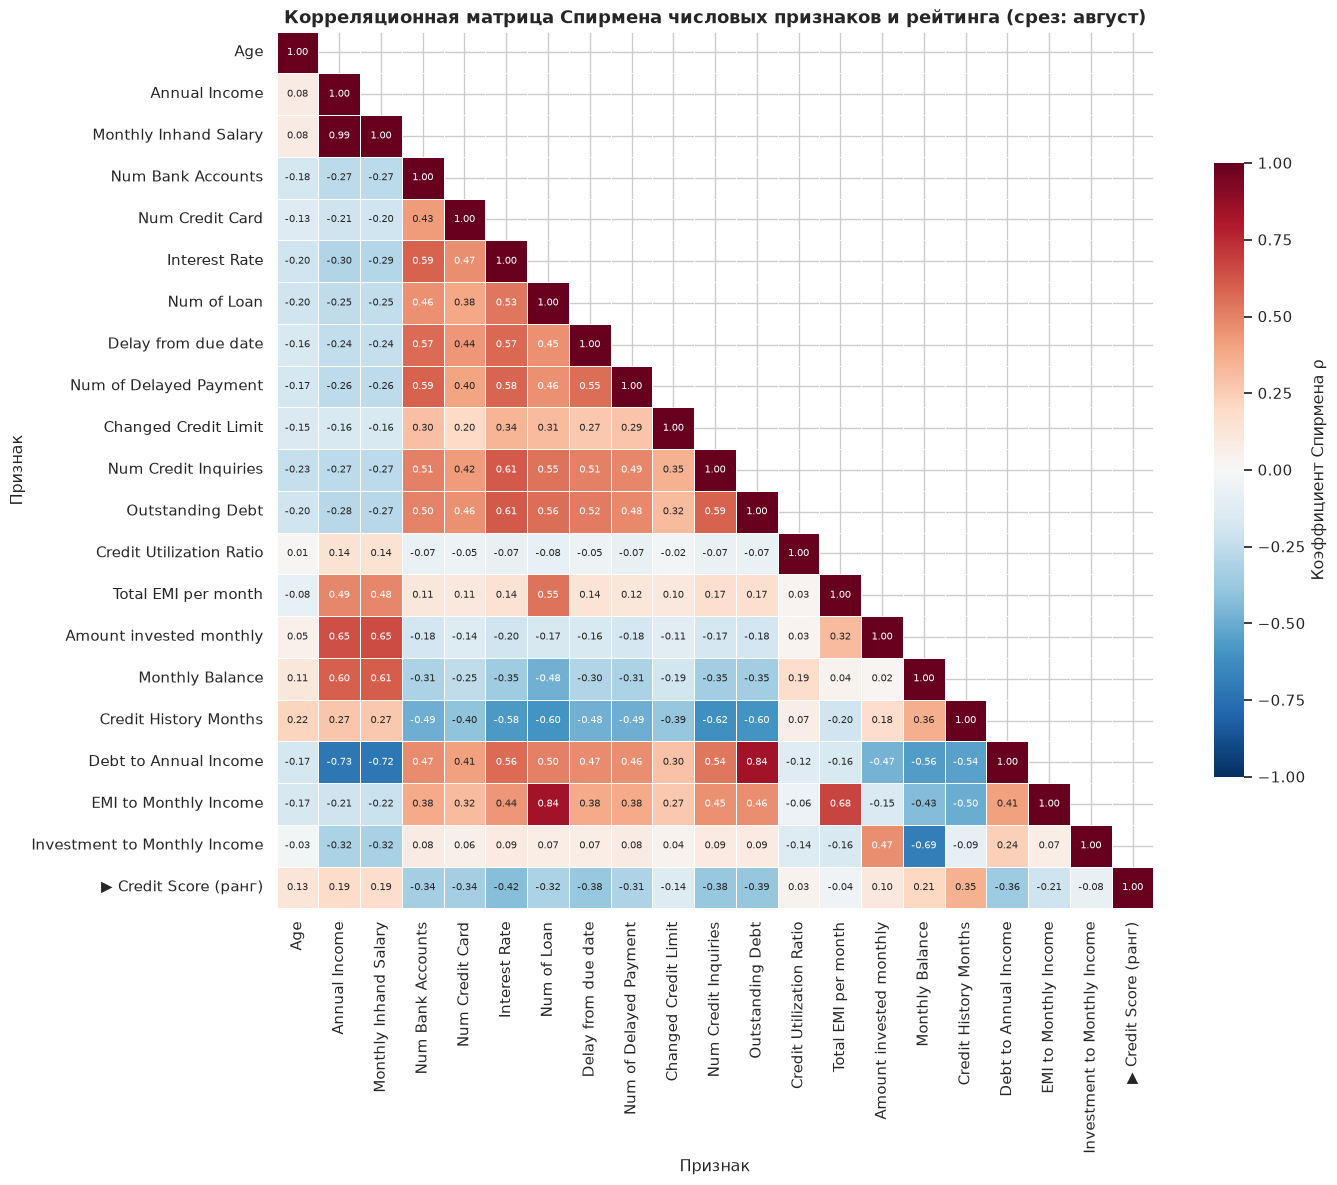

In [35]:
short = {c: c.replace("_", " ") for c in corr.columns}
short["Score_Rank"] = "▶ Credit Score (ранг)"

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr.rename(index=short, columns=short), mask=mask, cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.4, square=True,
            cbar_kws={"label": "Коэффициент Спирмена ρ", "shrink": 0.7}, ax=ax)
ax.set_title("Корреляционная матрица Спирмена числовых признаков и рейтинга (срез: август)", fontsize=13)
ax.set_xlabel("Признак")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

Последняя строка карты – связь с рейтингом: наиболее насыщенные отрицательные клетки у ставки (−0,42), долга (−0,39), просрочки и числа запросов (−0,38), положительная – у длительности истории (+0,35). Признаки «рискованного профиля» (ставка, запросы, число карт, счетов и кредитов, просрочки) положительно связаны между собой. Самая тёмная клетка вне диагонали – годовой и месячный доход (0,99): признаки дублируют друг друга.

## 3. Поиск закономерностей

### 3.1. Различия между классами рейтинга: гипотезы H1–H5

**Методы** (на срезе, n = 12 500 независимых клиентов, α = 0.05):

- Числовой признак × 3 класса рейтинга → **критерий Краскела–Уоллиса** (непараметрический аналог однофакторного ANOVA; выбран, т.к. распределения ненормальны). H₀: распределения признака одинаковы во всех классах. Размер эффекта — $\varepsilon^2 = \frac{H - k + 1}{n - k}$: 0.01 — малый, 0.06 — средний, 0.14 — большой.
- Категориальный признак × рейтинг → **критерий χ² Пирсона** для таблицы сопряжённости. Размер эффекта — **V Крамера**: 0.1 — слабая связь, 0.3 — умеренная, 0.5 — сильная.
- Так как проверяется много гипотез одновременно, применяем **поправку Бонферрони** (порог α / m).

При n = 12 500 даже ничтожный эффект будет «значимым», поэтому выводы делаем **по размеру эффекта**, а не только по p-value.

In [36]:
def kruskal_test(frame, column):
    groups = [frame.loc[frame["Credit_Score"] == score, column] for score in SCORE_ORDER]
    h_stat, p_value = stats.kruskal(*groups)
    n, k = len(frame), len(groups)
    medians = frame.groupby("Credit_Score", observed=True)[column].median().reindex(SCORE_ORDER)
    return {"тест": "Краскел–Уоллис", "статистика": h_stat, "p-value": p_value,
            "эффект": (h_stat - k + 1) / (n - k), "мера эффекта": "ε²",
            "Good": medians["Good"], "Standard": medians["Standard"], "Poor": medians["Poor"]}

def chi2_test(frame, column):
    table = pd.crosstab(frame[column], frame["Credit_Score"])
    chi2, p_value, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return {"тест": "χ²", "статистика": chi2, "p-value": p_value,
            "эффект": cramers_v, "мера эффекта": "V Крамера"}

def effect_strength(row):
    e = row["эффект"]
    if row["мера эффекта"] == "ε²":
        return "большой" if e >= 0.14 else "средний" if e >= 0.06 else "малый" if e >= 0.01 else "нет"
    return "сильная" if e >= 0.5 else "умеренная" if e >= 0.3 else "слабая" if e >= 0.1 else "нет"

TESTS = [
    ("H1", "Outstanding_Debt", kruskal_test),
    ("H1", "Delay_from_due_date", kruskal_test),
    ("H1", "Num_of_Delayed_Payment", kruskal_test),
    ("H2", "Interest_Rate", kruskal_test),
    ("H3", "Credit_Mix", chi2_test),
    ("H4", "Num_Credit_Inquiries", kruskal_test),
    ("H5", "EMI_to_Monthly_Income", kruskal_test),
    ("доп.", "Credit_History_Months", kruskal_test),
    ("доп.", "Annual_Income", kruskal_test),
    ("доп.", "Age", kruskal_test),
    ("доп.", "Payment_of_Min_Amount", chi2_test),
    ("доп.", "Payment_Behaviour", chi2_test),
    ("доп.", "Occupation", chi2_test),
]
results = pd.DataFrame([{"гипотеза": h, "признак": col, **fn(snapshot, col)} for h, col, fn in TESTS])
bonferroni_alpha = 0.05 / len(results)
results["значимо (Бонферрони)"] = np.where(results["p-value"] < bonferroni_alpha, "да", "нет")
results["сила эффекта"] = results.apply(effect_strength, axis=1)
print(f"Порог с поправкой Бонферрони: α = 0.05 / {len(results)} = {bonferroni_alpha:.4f}")
results.set_index(["гипотеза", "признак"]).style.format({
    "статистика": "{:,.1f}", "p-value": "{:.1e}", "эффект": "{:.3f}",
    "Good": "{:,.3f}", "Standard": "{:,.3f}", "Poor": "{:,.3f}",
}, na_rep="—")

Порог с поправкой Бонферрони: α = 0.05 / 13 = 0.0038


#### H3 подробнее: структура рейтинга внутри `Credit_Mix`

In [37]:
# H3 подробнее: доля каждого рейтинга внутри категории Credit_Mix.
mix_table = (pd.crosstab(snapshot["Credit_Mix"], snapshot["Credit_Score"], normalize="index")
             .reindex(index=["Good", "Standard", "Bad"], columns=SCORE_ORDER).mul(100))
display(mix_table.round(1).rename_axis(index="Credit_Mix", columns="Credit_Score, %"))

# Отношение шансов «Poor vs не Poor» для Bad против остальных категорий.
bad = snapshot["Credit_Mix"] == "Bad"
poor = snapshot["Credit_Score"] == "Poor"
odds_ratio, p_fisher = stats.fisher_exact(pd.crosstab(bad, poor).values)
print(f"Отношение шансов оказаться Poor при Credit_Mix=Bad: OR = {odds_ratio:.2f}, p = {p_fisher:.1e}")

"Credit_Score, %",Good,Standard,Poor
Credit_Mix,,,
Good,44.600,39.400,16.000
Standard,11.100,65.400,23.400
Bad,2.800,41.700,55.600


Отношение шансов оказаться Poor при Credit_Mix=Bad: OR = 4.86, p = 5.5e-278


#### Ранжирование факторов: кандидаты в топ-5

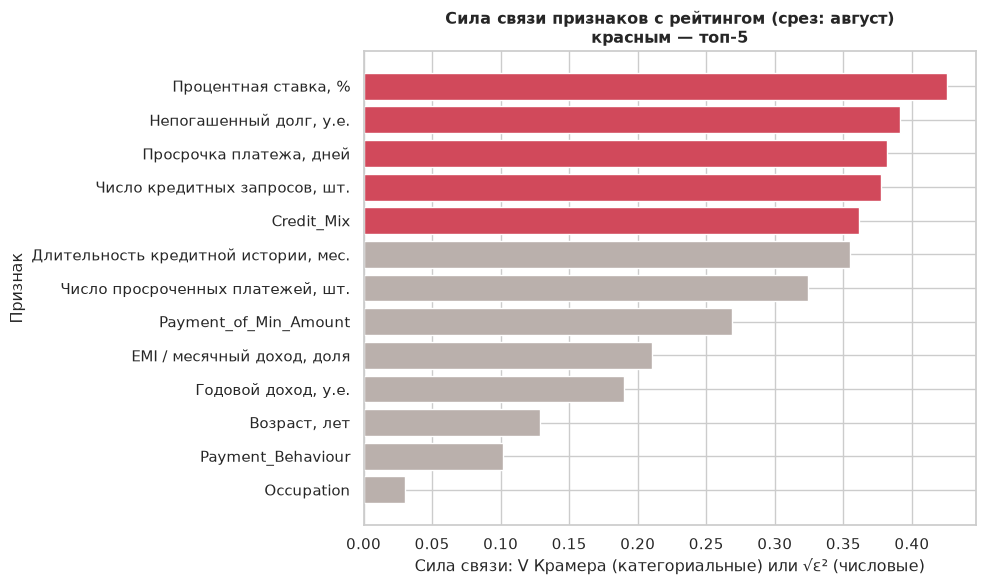

,признак,мера эффекта,эффект,сопоставимая сила (√ε² или V)
1,Interest_Rate,ε²,0.181,0.425
2,Outstanding_Debt,ε²,0.153,0.392
3,Delay_from_due_date,ε²,0.146,0.382
4,Num_Credit_Inquiries,ε²,0.143,0.378
5,Credit_Mix,V Крамера,0.361,0.361
6,Credit_History_Months,ε²,0.126,0.355
7,Num_of_Delayed_Payment,ε²,0.105,0.324
8,Payment_of_Min_Amount,V Крамера,0.269,0.269
9,EMI_to_Monthly_Income,ε²,0.044,0.210
10,Annual_Income,ε²,0.036,0.190


In [38]:
# Ранжирование факторов по размеру эффекта — кандидаты в топ-5 для ЛР3.
# Чтобы сравнивать ε² и V на одной шкале, переводим ε² в эквивалент корреляции √ε².
ranking = results[["признак", "мера эффекта", "эффект"]].copy()
ranking["сопоставимая сила (√ε² или V)"] = np.where(
    ranking["мера эффекта"] == "ε²", np.sqrt(ranking["эффект"]), ranking["эффект"])
ranking = ranking.sort_values("сопоставимая сила (√ε² или V)", ascending=False).reset_index(drop=True)
ranking.index += 1

fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = [SCORE_COLORS["Poor"] if i < 5 else "#bab0ac" for i in range(len(ranking))]
ax.barh([label(c) for c in ranking["признак"]][::-1],
        ranking["сопоставимая сила (√ε² или V)"][::-1], color=bar_colors[::-1])
ax.set_title("Сила связи признаков с рейтингом (срез: август)\nкрасным — топ-5")
ax.set_xlabel("Сила связи: V Крамера (категориальные) или √ε² (числовые)")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()
ranking.round(3)

| Гипотеза | Результат | Обоснование |
|---|---|---|
| **H1** долг и просрочки | **подтверждена** | Медиана долга: `Good` 747 → `Standard` 1 041 → `Poor` 1 826 у.е.; просрочки: 11 → 18 → 26 дней. Краскел–Уоллис p < 10⁻³⁰⁰, ε² = 0.15 для обоих признаков — **большой эффект**. Число просроченных платежей (9 → 14 → 16) — средний эффект (ε² = 0.11). |
| **H2** процентная ставка | **подтверждена** | Медиана ставки: `Good` 8%, `Standard` 13%, `Poor` 20%; ε² = 0.18 — **наибольший эффект** среди всех признаков. |
| **H3** `Credit_Mix = Bad` | **подтверждена** | χ², p ≈ 0, V Крамера = 0.36 — **умеренная связь, самая сильная среди категориальных**. При `Bad` доля `Poor` 55.6%, `Good` — 2.8% (при `Good`: 16.0% и 44.6%). Отношение шансов оказаться `Poor` при `Bad` против остальных категорий OR = 4.86 (точный тест Фишера, p ≈ 10⁻²⁷⁸). |
| **H4** кредитные запросы | **подтверждена** | Медиана: 4 запроса у `Good`, 6 у `Standard`, 9 у `Poor`; ε² = 0.14 — **большой эффект**. |
| **H5** доля EMI в доходе | **подтверждена частично** | Различие статистически значимо (p ≈ 10⁻¹²⁰), направление совпадает с гипотезой (медиана 1.9% → 2.4% → 3.4% дохода), но ε² = 0.04 — **эффект малый**. Это слабый самостоятельный фактор. |

**Дополнительные находки:**
- `Payment_of_Min_Amount` — вторая по силе связь среди категориальных (V = 0.27): у клиентов, платящих только минимальный платёж (`Yes`), `Good` лишь у 6.9% против 36.6% у `No`. Неявный пропуск `NM` по доле `Poor` (29%) лежит между `No` (14%) и `Yes` (39%) — решение ЛР1 оставить его отдельной категорией оправдано.
- Длительность кредитной истории — средний/большой эффект (ε² = 0.13): медиана 285 мес. у `Good` против 170 у `Poor`.
- Доход и возраст значимы, но эффект малый (ε² < 0.04).
- **Профессия не связана с рейтингом** (p ≈ 0.74 — H₀ не отвергается): при принятии решения её можно не учитывать.

**Кандидаты в топ-5 факторов** (по сопоставимой силе связи, график выше): `Interest_Rate`, `Outstanding_Debt`, `Delay_from_due_date`, `Num_Credit_Inquiries`, `Credit_Mix`; вплотную за ними — `Credit_History_Months`. Сравнение √ε² и V Крамера — приближённое, поэтому в ЛР3 сверим этот список с важностью признаков модели.

### 3.2. Временные паттерны

Набор содержит 8 месяцев (январь–август) одного года, поэтому полноценную сезонность (повторяющийся годовой цикл) проверить нельзя. Можно проверить **динамику внутри периода**: меняется ли распределение рейтинга и ключевых признаков по месяцам, и насколько рейтинг клиента стабилен.

#### Структура рейтинга по месяцам

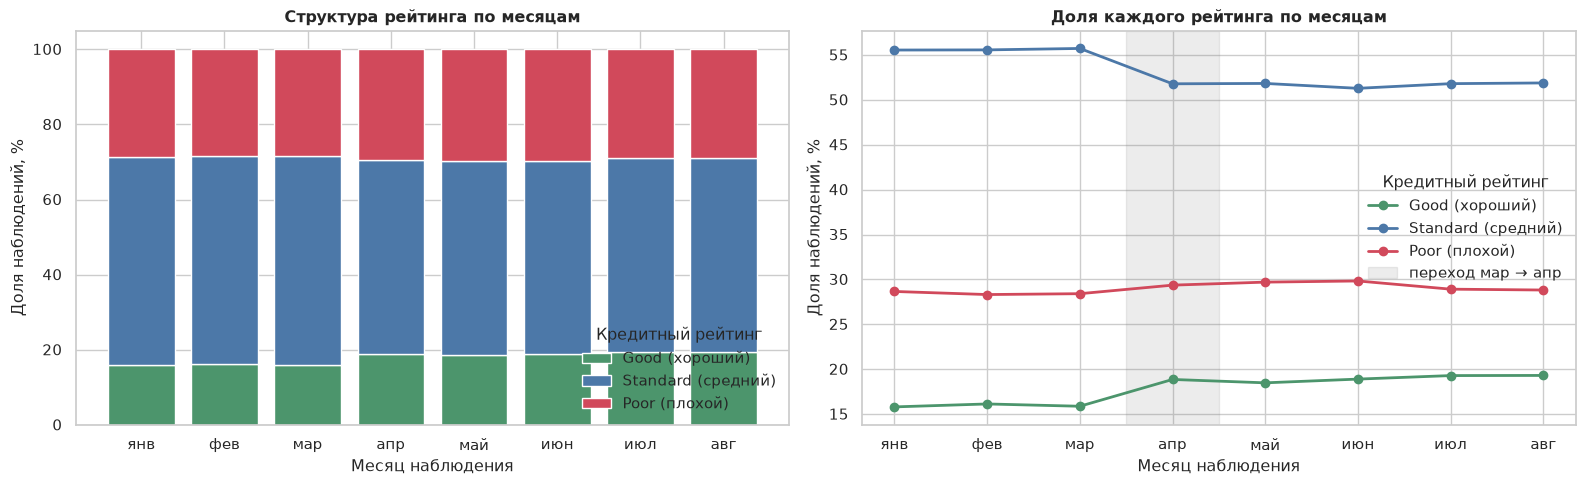

χ² независимости месяца и рейтинга: χ² = 201.8, df = 14, p = 2.3e-35
Средняя доля Good: янв–мар 15.9%, апр–авг 19.0%


In [39]:
MONTH_RU = {1: "янв", 2: "фев", 3: "мар", 4: "апр", 5: "май", 6: "июн", 7: "июл", 8: "авг"}

month_share = (pd.crosstab(df["Month_Number"], df["Credit_Score"], normalize="index")
               .reindex(columns=SCORE_ORDER).mul(100))
chi2, p_month, dof, _ = stats.chi2_contingency(pd.crosstab(df["Month_Number"], df["Credit_Score"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
bottom = np.zeros(len(month_share))
for score in SCORE_ORDER:
    axes[0].bar(month_share.index.map(MONTH_RU), month_share[score], bottom=bottom,
                color=SCORE_COLORS[score], label=SCORE_RU[score], edgecolor="white")
    bottom += month_share[score].values
axes[0].set_title("Структура рейтинга по месяцам")
axes[0].set_xlabel("Месяц наблюдения")
axes[0].set_ylabel("Доля наблюдений, %")
axes[0].legend(title="Кредитный рейтинг", loc="lower right")

for score in SCORE_ORDER:
    axes[1].plot(month_share.index.map(MONTH_RU), month_share[score], marker="o",
                 color=SCORE_COLORS[score], label=SCORE_RU[score], linewidth=2)
axes[1].axvspan(2.5, 3.5, color="grey", alpha=0.15, label="переход мар → апр")
axes[1].set_title("Доля каждого рейтинга по месяцам")
axes[1].set_xlabel("Месяц наблюдения")
axes[1].set_ylabel("Доля наблюдений, %")
axes[1].legend(title="Кредитный рейтинг", loc="center right")
plt.tight_layout()
plt.show()

print(f"χ² независимости месяца и рейтинга: χ² = {chi2:.1f}, df = {dof}, p = {p_month:.1e}")
print(f"Средняя доля Good: янв–мар {month_share.loc[1:3, 'Good'].mean():.1f}%, "
      f"апр–авг {month_share.loc[4:8, 'Good'].mean():.1f}%")

#### Динамика признаков по месяцам

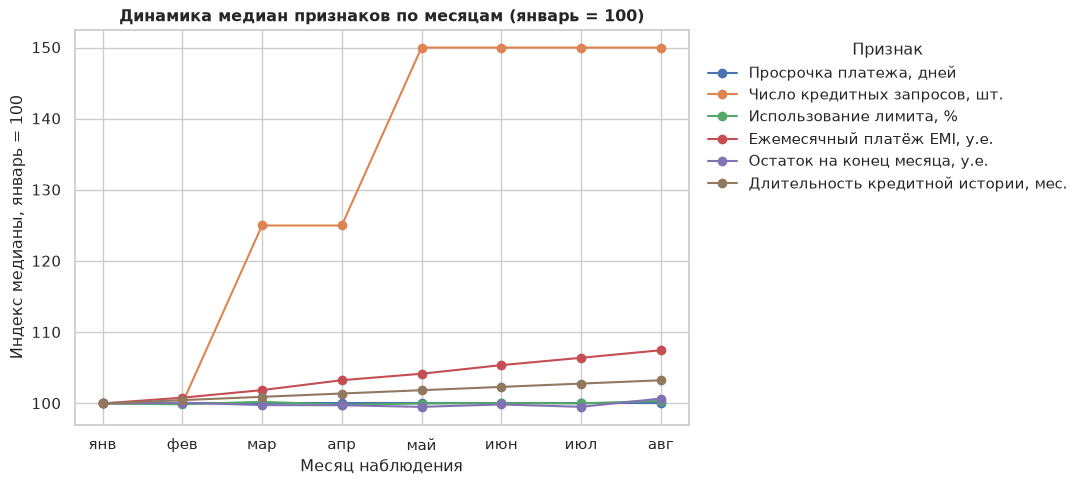

,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month,Monthly_Balance,Credit_History_Months
Month_Number,,,,,,
1,18.000,4.000,32.300,64.130,337.630,215.000
2,18.000,4.000,32.260,64.650,337.980,216.000
3,18.000,5.000,32.370,65.330,336.850,217.000
4,18.000,5.000,32.240,66.220,336.780,218.000
5,18.000,6.000,32.300,66.800,336.020,219.000
6,18.000,6.000,32.310,67.580,337.160,220.000
7,18.000,6.000,32.300,68.240,336.030,221.000
8,18.000,6.000,32.420,68.920,339.950,222.000


In [40]:
TIME_FEATURES = ["Delay_from_due_date", "Num_Credit_Inquiries", "Credit_Utilization_Ratio",
                 "Total_EMI_per_month", "Monthly_Balance", "Credit_History_Months"]
monthly_medians = df.groupby("Month_Number")[TIME_FEATURES].median()
monthly_index = monthly_medians / monthly_medians.loc[1] * 100

fig, ax = plt.subplots(figsize=(11, 5))
for column in TIME_FEATURES:
    ax.plot(monthly_index.index.map(MONTH_RU), monthly_index[column], marker="o", label=label(column))
ax.set_title("Динамика медиан признаков по месяцам (январь = 100)")
ax.set_xlabel("Месяц наблюдения")
ax.set_ylabel("Индекс медианы, январь = 100")
ax.legend(title="Признак", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
monthly_medians.round(2)

#### Стабильность рейтинга клиента

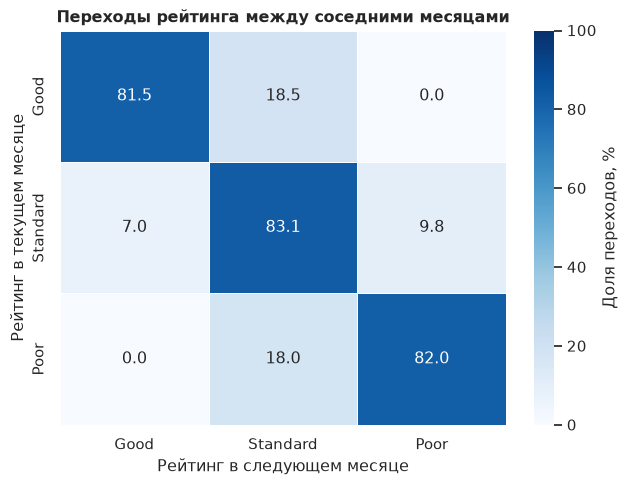

Рейтинг меняется в 17.5% переходов месяц → месяц
Хотя бы раз за 8 месяцев рейтинг менялся у 58.3% клиентов


In [41]:
# Стабильность рейтинга клиента: матрица переходов «рейтинг в месяц t → рейтинг в месяц t+1».
ordered = df.sort_values(["Customer_ID", "Month_Number"])
ordered["Next_Score"] = ordered.groupby("Customer_ID")["Credit_Score"].shift(-1)
transitions = ordered.dropna(subset=["Next_Score"])
transition_matrix = (pd.crosstab(transitions["Credit_Score"], transitions["Next_Score"], normalize="index")
                     .reindex(index=SCORE_ORDER, columns=SCORE_ORDER).mul(100))

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(transition_matrix, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "Доля переходов, %"}, ax=ax, linewidths=0.5)
ax.set_title("Переходы рейтинга между соседними месяцами")
ax.set_xlabel("Рейтинг в следующем месяце")
ax.set_ylabel("Рейтинг в текущем месяце")
plt.tight_layout()
plt.show()

changed = (transitions["Credit_Score"].astype(str) != transitions["Next_Score"].astype(str)).mean()
clients_changed = (df.groupby("Customer_ID")["Credit_Score"].nunique() > 1).mean()
print(f"Рейтинг меняется в {changed:.1%} переходов месяц → месяц")
print(f"Хотя бы раз за 8 месяцев рейтинг менялся у {clients_changed:.1%} клиентов")

- **Скачок в апреле:** доля `Good` в среднем 15.9% в январе–марте и 19.0% в апреле–августе, доля `Standard` соответственно падает с ≈ 55.6% до ≈ 51.8%. Внутри каждого из двух периодов доли почти постоянны. Различие статистически значимо (χ², p ≪ 0.05), но по величине небольшое (≈ 3 п.п.). Это похоже не на сезонность, а на **изменение методики присвоения рейтинга с апреля** или на особенность генерации данных — вопрос к заказчику.
- **Число кредитных запросов растёт:** медиана 4 в январе–феврале → 5 в марте–апреле → 6 с мая (+50%). Ступенчатый рост согласуется с тем, что запросы накапливаются. `Total_EMI_per_month` плавно растёт на ≈ 1% в месяц (+7.5% за период), `Credit_History_Months` — по построению на 1 месяц в месяц.
- **Просрочка, использование лимита и остаток постоянны** (индекс ≈ 100) — сезонных колебаний поведения нет.
- **Рейтинг клиента достаточно стабилен:** в 82.5% случаев он не меняется от месяца к месяцу; наиболее частые переходы — между соседними классами (`Standard` ↔ `Good`, `Standard` ↔ `Poor`), прямых переходов `Good` ↔ `Poor` за один месяц нет вовсе. При этом у ≈ 58% клиентов рейтинг хотя бы раз менялся за 8 месяцев.
- **Следствие для ЛР3:** наблюдения одного клиента очень похожи, поэтому при случайном разбиении на train/test один и тот же клиент попадёт в обе части, и качество модели будет завышено. Разбивать нужно **по клиентам** (`GroupShuffleSplit` / `GroupKFold`).

### 3.3. Сезонные паттерны

Данные покрывают только январь–август одного года, поэтому повторяющийся годовой цикл проверить нельзя. Можно сравнить календарные сезоны внутри периода: зима (январь–февраль), весна (март–май), лето (июнь–август). Сезоны неполные: зима – 2 месяца, весна и лето – по 3.

Credit_Score,Good,Standard,Poor,Наблюдений
Season,,,,
зима,16.000,55.600,28.500,25000
весна,17.700,53.100,29.200,37500
лето,19.200,51.700,29.200,37500


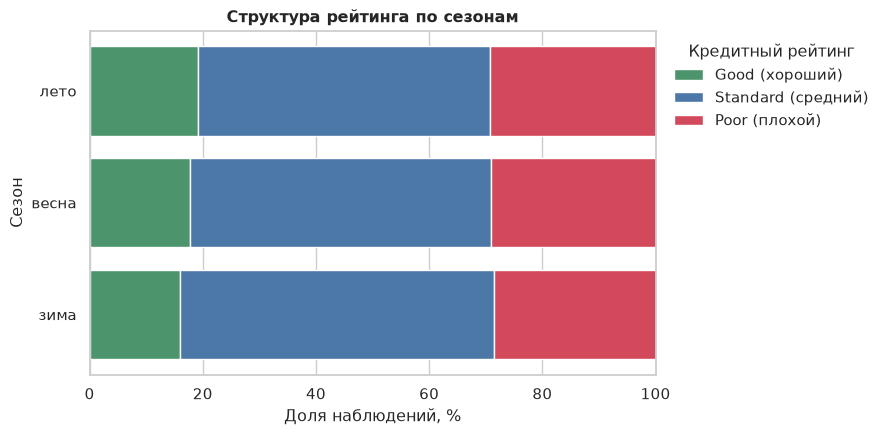

Доля Good в марте: 15.9%; в апреле–мае: 18.7%


In [42]:
SEASON = {1: "зима", 2: "зима", 3: "весна", 4: "весна", 5: "весна", 6: "лето", 7: "лето", 8: "лето"}
SEASON_ORDER = ["зима", "весна", "лето"]
df["Season"] = pd.Categorical(df["Month_Number"].map(SEASON), categories=SEASON_ORDER, ordered=True)

season_share = (pd.crosstab(df["Season"], df["Credit_Score"], normalize="index")
                .reindex(columns=SCORE_ORDER).mul(100))
season_stats = season_share.assign(**{"Наблюдений": df["Season"].value_counts().reindex(SEASON_ORDER)})
display(season_stats.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(season_share))
for score in SCORE_ORDER:
    ax.barh(season_share.index.astype(str), season_share[score], left=left,
            color=SCORE_COLORS[score], label=SCORE_RU[score], edgecolor="white")
    left += season_share[score].values
ax.set_title("Структура рейтинга по сезонам")
ax.set_xlabel("Доля наблюдений, %")
ax.set_ylabel("Сезон")
ax.set_xlim(0, 100)
ax.legend(title="Кредитный рейтинг", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

march = df["Month_Number"].eq(3)
print(f"Доля Good в марте: {(df.loc[march, 'Credit_Score'] == 'Good').mean():.1%}; "
      f"в апреле–мае: {(df.loc[df['Month_Number'].isin([4, 5]), 'Credit_Score'] == 'Good').mean():.1%}")

Доля `Good` растёт от зимы к лету: 16,0% → 17,7% → 19,2%. Но это не сезонный эффект: в марте доля `Good` такая же, как зимой (15,9%), а рост начинается скачком с апреля (апрель–май – 18,7%). Различие сезонов – следствие ступеньки в апреле из раздела 3.2. Годовую сезонность на 8 месяцах подтвердить или опровергнуть нельзя.

## 4. Визуализация данных

Гистограммы, Q-Q-графики, боксплоты выбросов и heatmap корреляций приведены выше, рядом со своими расчётами. Ниже – итоговые графики связи признаков с рейтингом. Единый стиль: палитра классов (`Good` – зелёный, `Standard` – синий, `Poor` – красный), подписанные оси с единицами и легенды.

### 4.1. Гистограммы по классам рейтинга

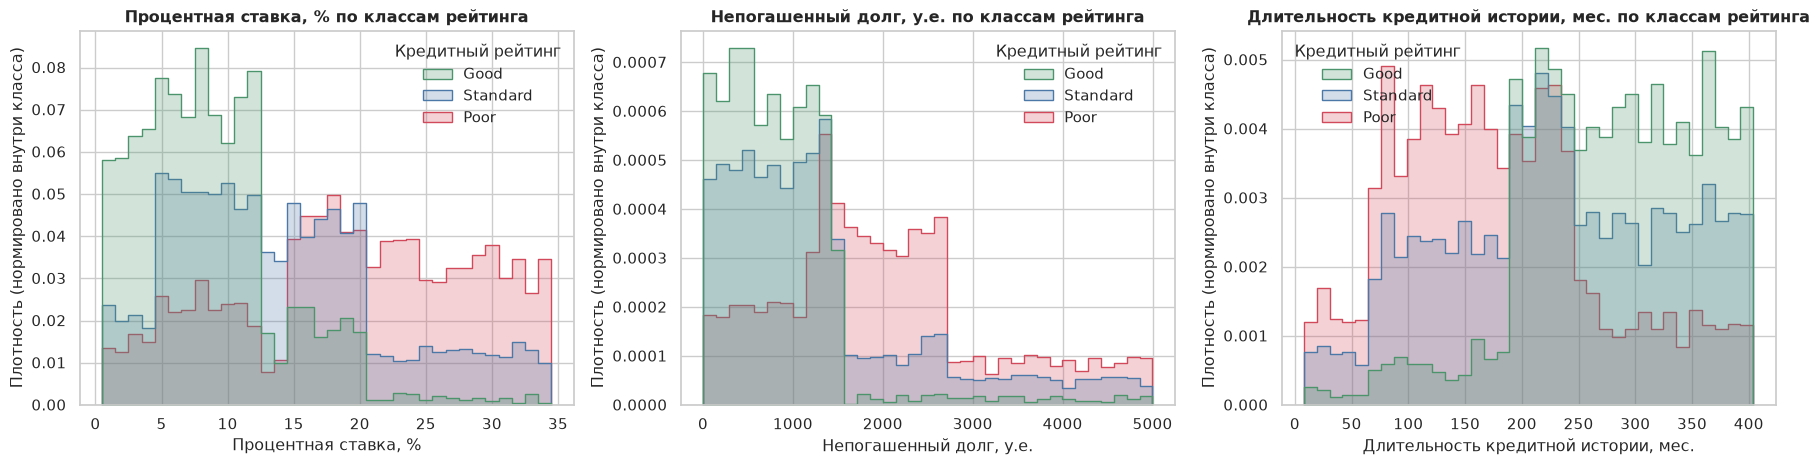

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, column in zip(axes, ["Interest_Rate", "Outstanding_Debt", "Credit_History_Months"]):
    sns.histplot(data=snapshot, x=column, hue="Credit_Score", hue_order=SCORE_ORDER,
                 palette=SCORE_COLORS, element="step", stat="density", common_norm=False,
                 discrete=(column == "Interest_Rate"), bins="auto" if column == "Interest_Rate" else 35,
                 ax=ax, alpha=0.25)
    ax.set_title(f"{label(column)} по классам рейтинга")
    ax.set_xlabel(label(column))
    ax.set_ylabel("Плотность (нормировано внутри класса)")
    ax.get_legend().set_title("Кредитный рейтинг")
plt.tight_layout()
plt.show()

Распределения классов сдвинуты друг относительно друга: у `Poor` ставка и долг смещены вправо, а кредитная история — влево. По ставке `Good` почти полностью сосредоточен в диапазоне 1–12%, а основная масса `Poor` — выше 15%; `Standard` перекрывается с обоими классами. По долгу видна граница около 1 500 у.е.: выше неё `Good` почти не встречается.

### 4.2. Боксплоты: ключевые признаки по классам

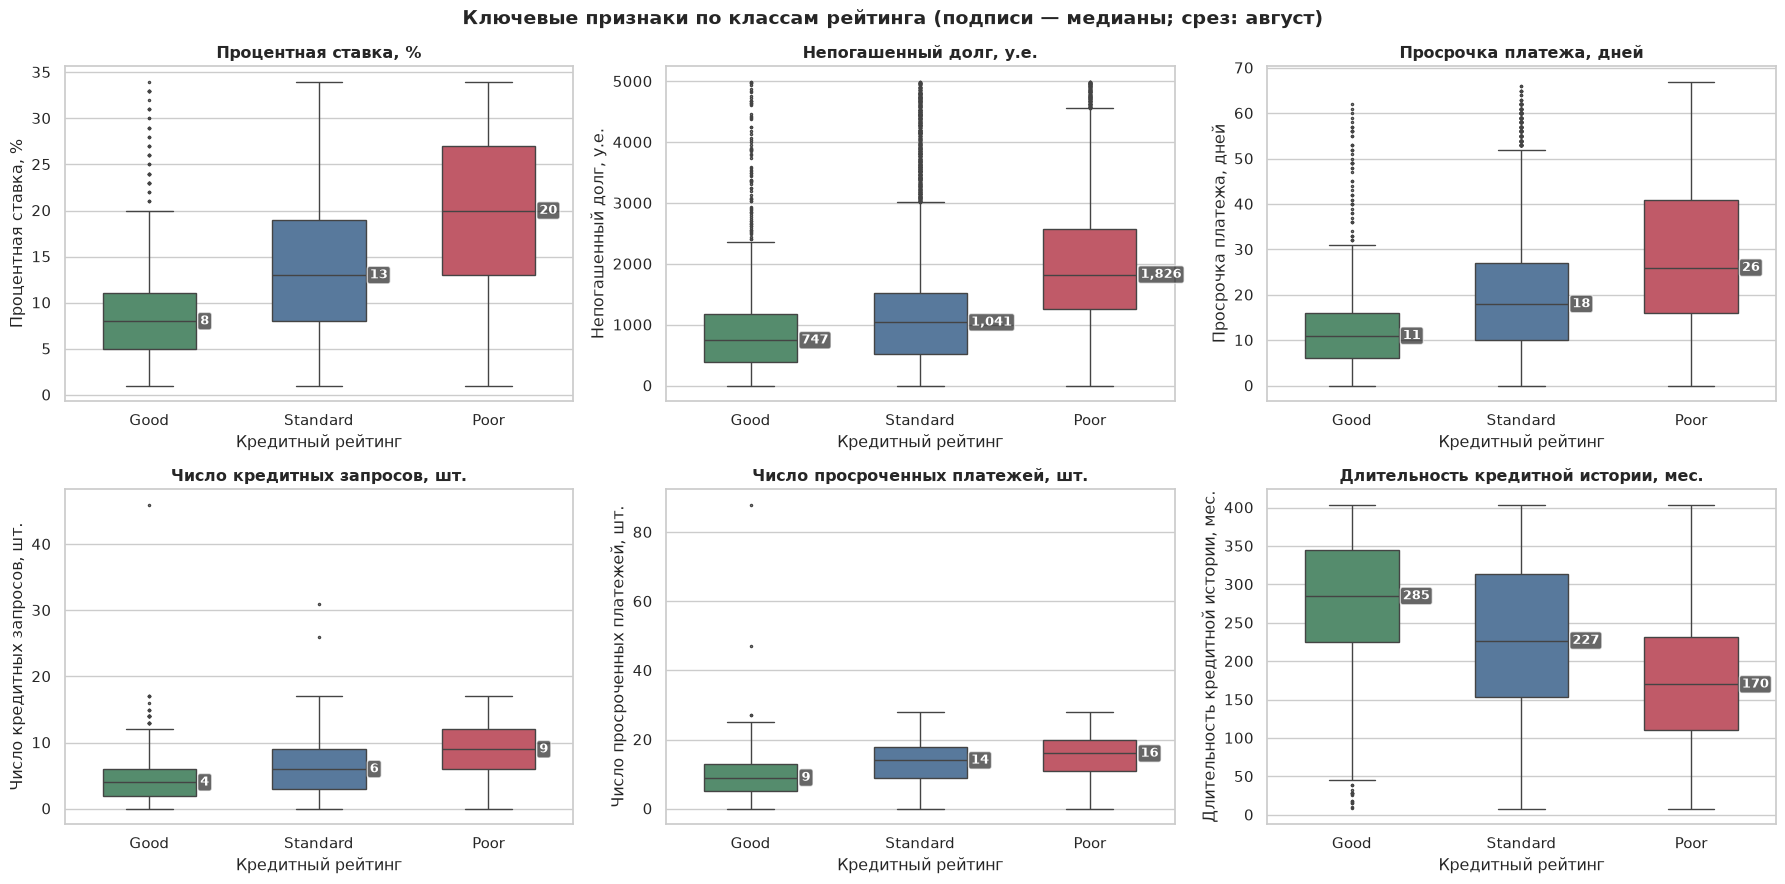

In [44]:
BOX_FEATURES = ["Interest_Rate", "Outstanding_Debt", "Delay_from_due_date",
                "Num_Credit_Inquiries", "Num_of_Delayed_Payment", "Credit_History_Months"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, column in zip(axes.flat, BOX_FEATURES):
    sns.boxplot(data=snapshot, x="Credit_Score", y=column, hue="Credit_Score", order=SCORE_ORDER,
                palette=SCORE_COLORS, legend=False, dodge=False, fliersize=1.5, width=0.55, ax=ax)
    medians = snapshot.groupby("Credit_Score", observed=True)[column].median().reindex(SCORE_ORDER)
    for i, value in enumerate(medians):
        ax.text(i + 0.3, value, f"{value:,.0f}", ha="left", va="center", fontsize=9,
                fontweight="bold", color="white",
                bbox={"boxstyle": "round,pad=0.2", "facecolor": "black", "alpha": 0.6})
    ax.set_title(f"{label(column)}")
    ax.set_xlabel("Кредитный рейтинг")
    ax.set_ylabel(label(column))
fig.suptitle("Ключевые признаки по классам рейтинга (подписи — медианы; срез: август)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Во всех шести признаках медиана монотонно изменяется в ряду `Good` → `Standard` → `Poor`, что согласуется с H1, H2, H4. Межквартильные размахи `Good` и `Poor` почти не перекрываются по ставке и числу запросов, а `Standard` занимает промежуточное положение — именно его модели будет сложнее всего отделять.

### 4.3. Violin plot: форма распределения внутри классов

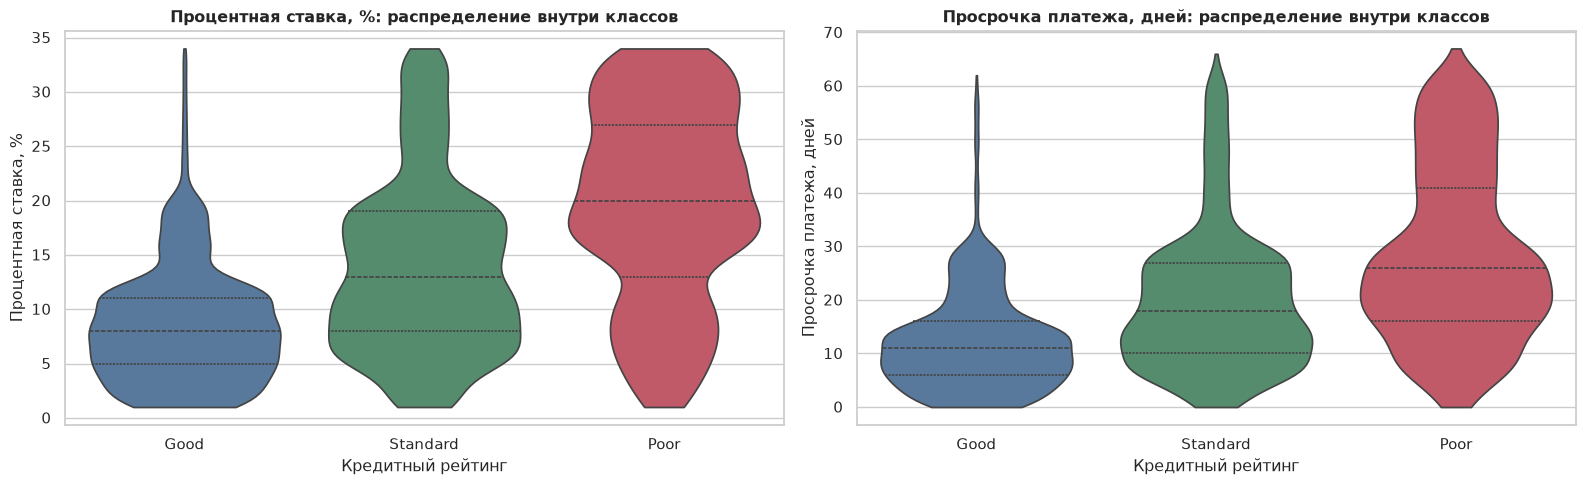

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, column in zip(axes, ["Interest_Rate", "Delay_from_due_date"]):
    sns.violinplot(data=snapshot, x="Credit_Score", y=column, hue="Credit_Score", order=SCORE_ORDER,
                   palette=SCORE_COLORS, legend=False, dodge=False, inner="quartile", cut=0, ax=ax)
    ax.set_title(f"{label(column)}: распределение внутри классов")
    ax.set_xlabel("Кредитный рейтинг")
    ax.set_ylabel(label(column))
plt.tight_layout()
plt.show()

Violin plot показывает то, что скрывает боксплот: у `Good` распределение ставки **унимодальное** с острым пиком около 5–8%, у `Poor` — широкое и плоское (15–34%). Распределение просрочки у `Good` сосредоточено в районе 0–15 дней, у `Poor` — растянуто до 60+ дней.

### 4.4. Boxen plot: тяжёлый хвост платежей

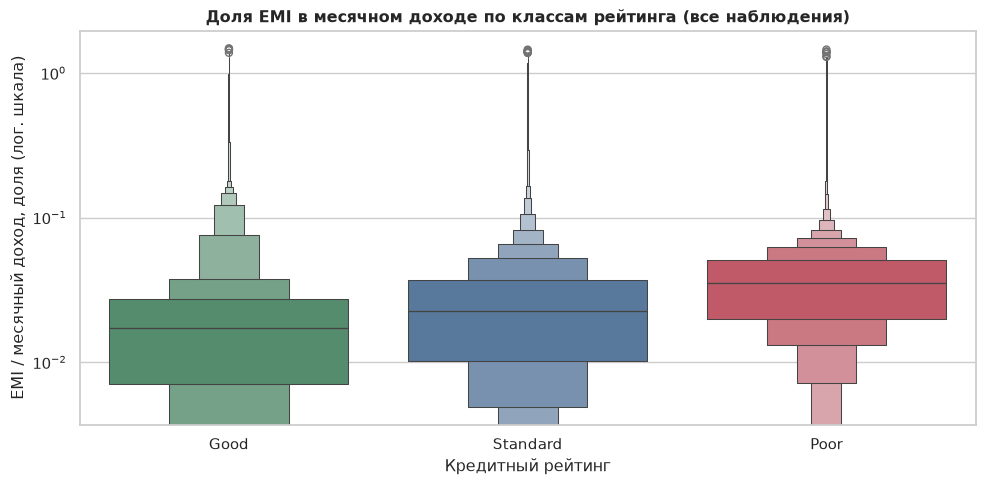

In [46]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxenplot(data=df, x="Credit_Score", y="EMI_to_Monthly_Income", hue="Credit_Score",
              order=SCORE_ORDER, palette=SCORE_COLORS, legend=False, dodge=False, ax=ax)
ax.set_yscale("log")
ax.set_title("Доля EMI в месячном доходе по классам рейтинга (все наблюдения)")
ax.set_xlabel("Кредитный рейтинг")
ax.set_ylabel("EMI / месячный доход, доля (лог. шкала)")
plt.tight_layout()
plt.show()

Boxen plot (letter-value plot) выбран для признака с тяжёлым хвостом: он показывает больше квантилей, чем боксплот, и не превращает хвост в «облако» точек. Медиана доли EMI у `Poor` выше, но распределения классов сильно перекрываются — визуальное подтверждение **малого** эффекта по H5.

### 4.5. Диаграммы рассеяния (Scatter plot)

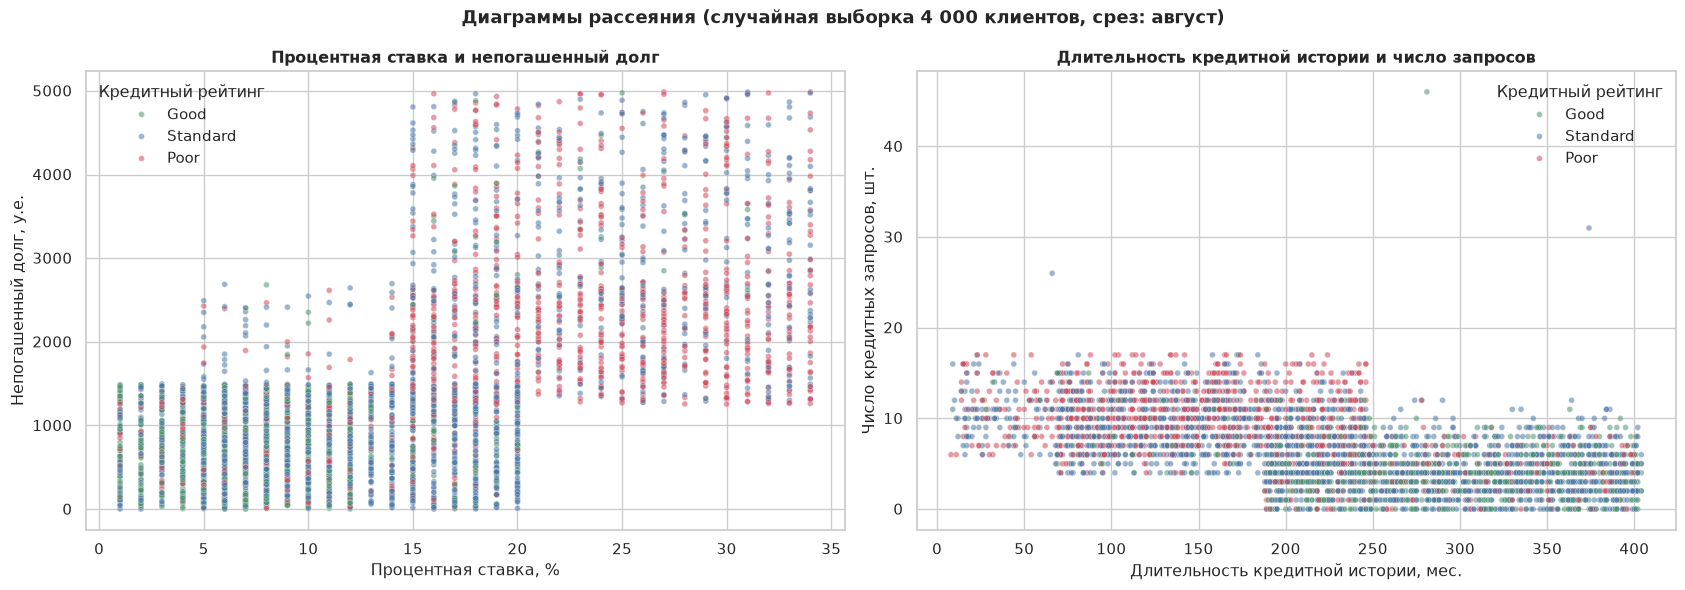

In [47]:
sample = snapshot.sample(4000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.scatterplot(data=sample, x="Interest_Rate", y="Outstanding_Debt", hue="Credit_Score",
                hue_order=SCORE_ORDER, palette=SCORE_COLORS, alpha=0.55, s=18, ax=axes[0])
axes[0].set_title("Процентная ставка и непогашенный долг")
axes[0].set_xlabel(label("Interest_Rate"))
axes[0].set_ylabel(label("Outstanding_Debt"))
axes[0].legend(title="Кредитный рейтинг")

sns.scatterplot(data=sample, x="Credit_History_Months", y="Num_Credit_Inquiries", hue="Credit_Score",
                hue_order=SCORE_ORDER, palette=SCORE_COLORS, alpha=0.55, s=18, ax=axes[1])
axes[1].set_title("Длительность кредитной истории и число запросов")
axes[1].set_xlabel(label("Credit_History_Months"))
axes[1].set_ylabel(label("Num_Credit_Inquiries"))
axes[1].legend(title="Кредитный рейтинг")
fig.suptitle("Диаграммы рассеяния (случайная выборка 4 000 клиентов, срез: август)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

- **Ставка × долг:** связь положительная и **ступенчатая**: при ставке до 14% долг почти не превышает ~1 500 у.е., и здесь преобладают `Good`/`Standard`; при ставке 15–20% появляются долги до 5 000 у.е.; при ставке выше 20% долг не опускается ниже ~1 300 у.е., и преобладает `Poor`. Такие резкие «блоки» — ещё один признак синтетической генерации данных.
- **История × запросы:** отрицательная связь (ρ = −0.62) с порогом около 250 месяцев: при более длинной истории запросов обычно не больше 9, и `Poor` встречается реже; при короткой истории — 4–17 запросов и много `Poor`.
- На обоих графиках классы пересекаются в средней зоне — двух признаков недостаточно для уверенной классификации, нужна многомерная модель.

### 4.6. Категориальные признаки

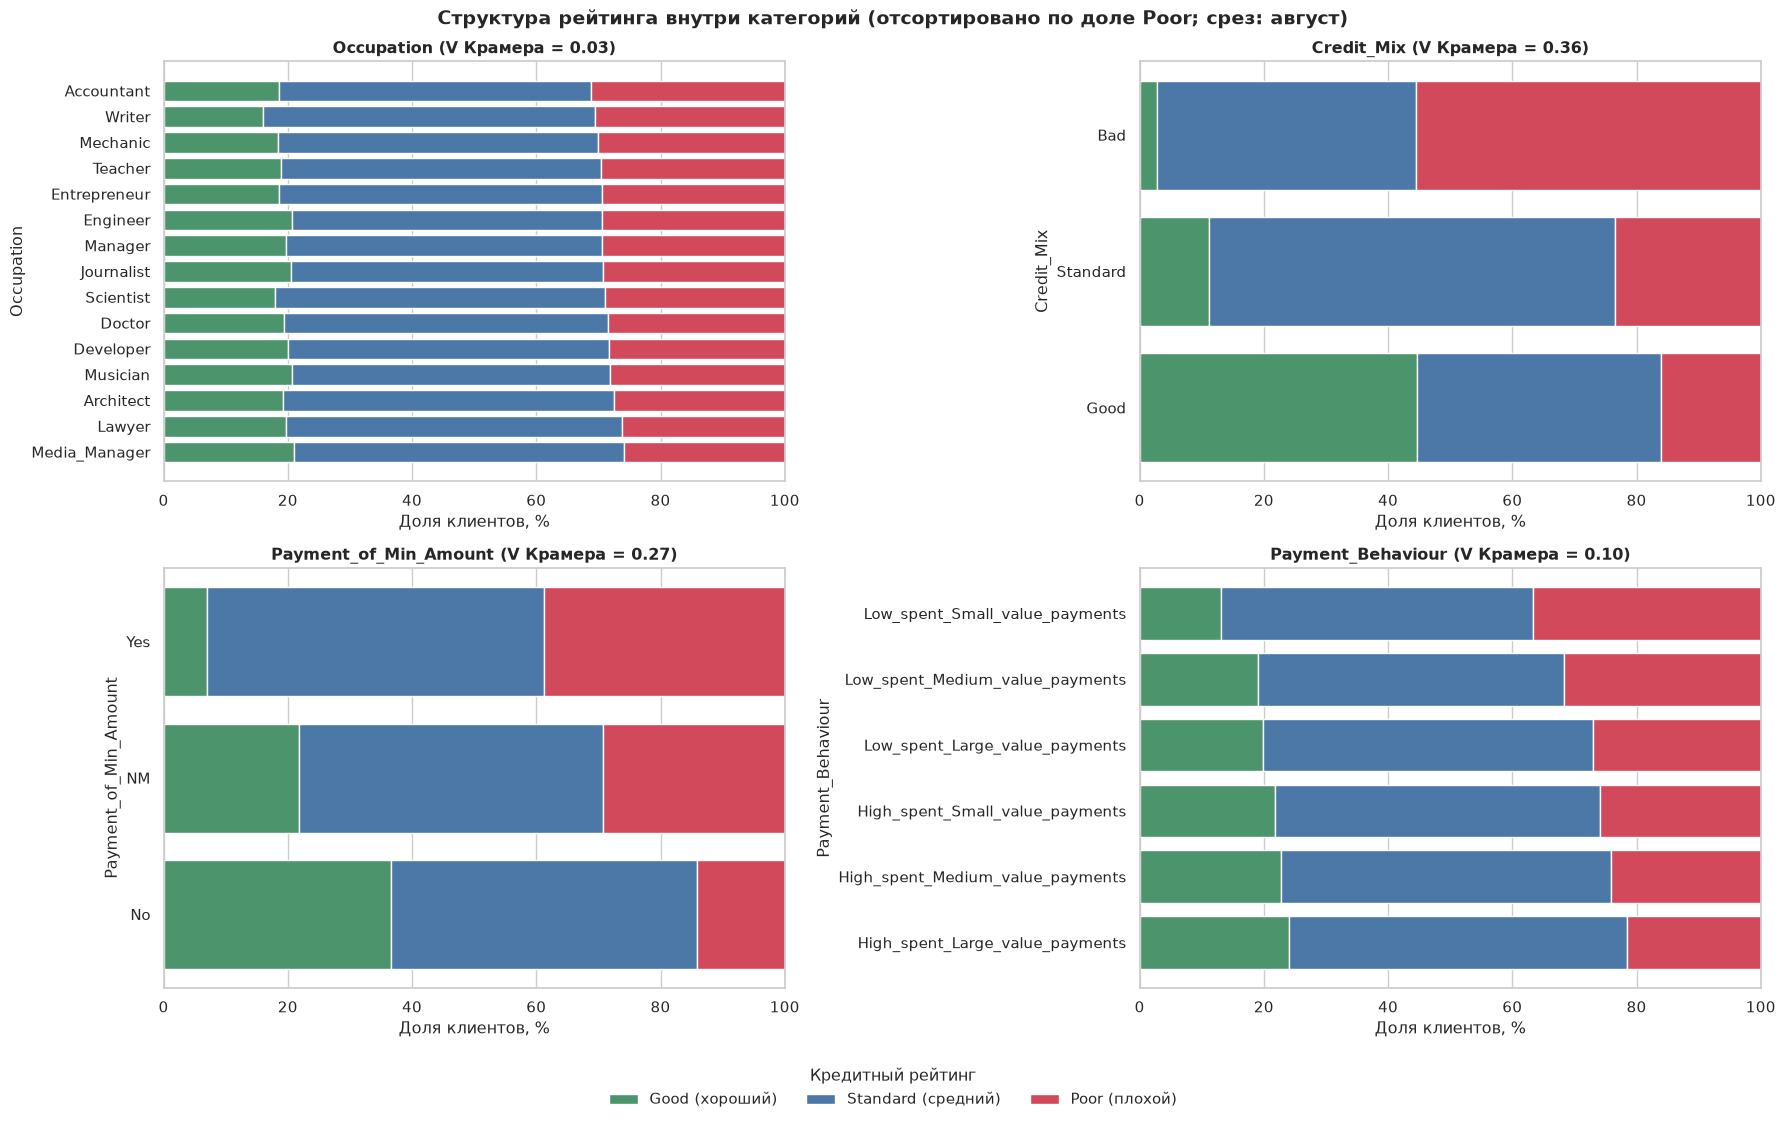

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, column in zip(axes.flat, CATEGORICAL):
    share = (pd.crosstab(snapshot[column], snapshot["Credit_Score"], normalize="index")
             .reindex(columns=SCORE_ORDER).mul(100).sort_values("Poor"))
    left = np.zeros(len(share))
    for score in SCORE_ORDER:
        ax.barh(share.index, share[score], left=left, color=SCORE_COLORS[score],
                label=SCORE_RU[score], edgecolor="white")
        left += share[score].values
    v = results.loc[results["признак"] == column, "эффект"].iloc[0]
    ax.set_title(f"{column} (V Крамера = {v:.2f})")
    ax.set_xlabel("Доля клиентов, %")
    ax.set_ylabel(column)
    ax.set_xlim(0, 100)
handles, labels_ = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels_, title="Кредитный рейтинг", loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Структура рейтинга внутри категорий (отсортировано по доле Poor; срез: август)",
             fontsize=14, fontweight="bold")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

Наглядно видна разница в силе связи: `Credit_Mix` и `Payment_of_Min_Amount` дают резко разную структуру рейтинга по категориям, `Payment_Behaviour` — слабую (больше всего `Poor` — около 37% — у сочетания «низкие траты + мелкие платежи», меньше всего — около 22% — у «высокие траты + крупные платежи»; т.е. активные клиенты с крупными платежами надёжнее), а у `Occupation` полосы почти одинаковы для всех 15 профессий — визуальное подтверждение отсутствия связи (p ≈ 0.74).

### 4.7. Heatmap: совместное влияние двух факторов

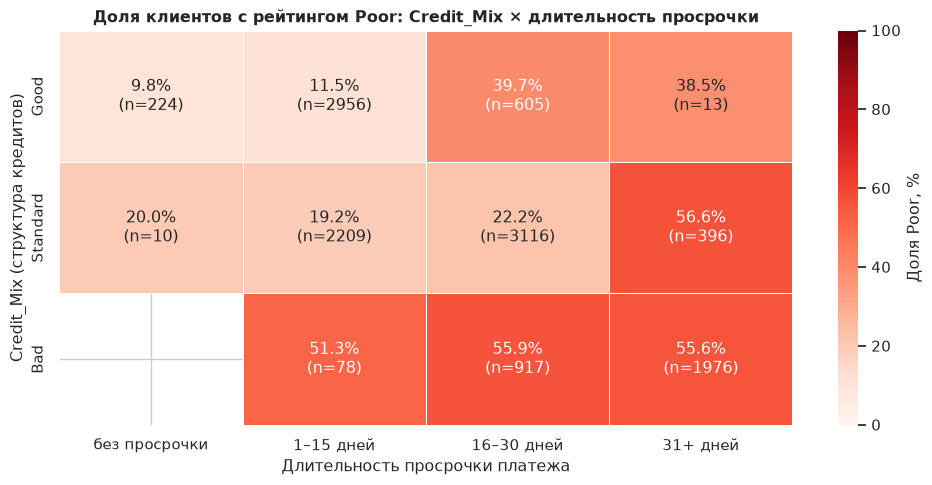

In [49]:
pivot = (snapshot.assign(is_poor=snapshot["Credit_Score"].eq("Poor"))
         .pivot_table(index="Credit_Mix", columns="Delay_Band", values="is_poor",
                      aggfunc="mean", observed=True)
         .reindex(index=["Good", "Standard", "Bad"],
                  columns=["без просрочки", "1–15 дней", "16–30 дней", "31+ дней"]) * 100)
counts = (snapshot.pivot_table(index="Credit_Mix", columns="Delay_Band", values="ID",
                               aggfunc="count", observed=True)
          .reindex(index=pivot.index, columns=pivot.columns))
annotations = pivot.round(1).astype(str) + "%\n(n=" + counts.fillna(0).astype(int).astype(str) + ")"

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot, annot=annotations, fmt="", cmap="Reds", vmin=0, vmax=100, linewidths=0.5,
            cbar_kws={"label": "Доля Poor, %"}, ax=ax)
ax.set_title("Доля клиентов с рейтингом Poor: Credit_Mix × длительность просрочки")
ax.set_xlabel("Длительность просрочки платежа")
ax.set_ylabel("Credit_Mix (структура кредитов)")
plt.tight_layout()
plt.show()

Факторы взаимодействуют: при `Credit_Mix = Good` и просрочке до 15 дней доля `Poor` всего ≈ 10–12%, но при просрочке 16+ дней она скачком растёт до ≈ 39%. При `Standard` доля `Poor` держится около 20%, пока просрочка не превысит 30 дней (тогда 57%). При `Bad` доля `Poor` высокая (51–56%) независимо от просрочки — структура кредитов уже «содержит» риск. Влияние одного признака зависит от значения другого — аргумент в пользу моделей, улавливающих взаимодействия (деревья, ансамбли). Клетка `Bad` × «без просрочки» пуста (таких клиентов нет), у `Good` × «31+ дней» всего 13 клиентов — оценку там следует считать ненадёжной.

## Вывод по ЛР2

In [50]:
def fmt_kw(column, percent=False):
    row = results.set_index("признак").loc[column]
    values = [row[s] * 100 if percent else row[s] for s in SCORE_ORDER]
    unit = "%" if percent else ""
    return (f"ε² = {row['эффект']:.3f}; медианы Good / Standard / Poor: "
            + " / ".join(f"{v:,.1f}{unit}" for v in values))

mix_v = results.set_index("признак").loc["Credit_Mix", "эффект"]
hypotheses = pd.DataFrame({
    "Гипотеза": [
        "Долг связан с худшим рейтингом", "Просрочка связана с худшим рейтингом",
        "Высокая ставка чаще у Poor", "Credit_Mix = Bad связан с худшим рейтингом",
        "Частые запросы связаны с худшим рейтингом", "Доля EMI в доходе связана с худшим рейтингом",
    ],
    "Результат": [
        "Подтверждается", "Подтверждается", "Подтверждается", "Подтверждается",
        "Подтверждается", "Подтверждается частично: эффект малый",
    ],
    "Основание": [
        fmt_kw("Outstanding_Debt"), fmt_kw("Delay_from_due_date"), fmt_kw("Interest_Rate"),
        f"V Крамера = {mix_v:.3f}; доля Poor при Bad {mix_table.loc['Bad', 'Poor']:.1f}%, OR = {odds_ratio:.2f}",
        fmt_kw("Num_Credit_Inquiries"), fmt_kw("EMI_to_Monthly_Income", percent=True),
    ],
}, index=["H1", "H1", "H2", "H3", "H4", "H5"])
hypotheses.index.name = "№"
display(hypotheses)

descriptive.to_csv(RESULTS / "descriptive_stats.csv", index_label="Признак")
normality.to_csv(RESULTS / "normality.csv")
outliers.to_csv(RESULTS / "outliers_iqr.csv", index_label="Признак")
corr.to_csv(RESULTS / "correlation_matrix.csv", index_label="Признак")
target_corr.rename("Спирмен с рейтингом").sort_values(key=abs, ascending=False).to_csv(
    RESULTS / "score_correlations.csv", index_label="Признак")
results.to_csv(RESULTS / "hypothesis_tests.csv", index=False)
ranking.to_csv(RESULTS / "factor_ranking.csv", index_label="Место")
month_share.to_csv(RESULTS / "score_by_month.csv", index_label="Месяц")
monthly_medians.to_csv(RESULTS / "medians_by_month.csv", index_label="Месяц")
transition_matrix.to_csv(RESULTS / "score_transitions.csv", index_label="Рейтинг сейчас")
season_stats.to_csv(RESULTS / "score_by_season.csv", index_label="Сезон")
hypotheses.to_csv(RESULTS / "hypotheses.csv")
print("Сохранено таблиц:", len(list(RESULTS.glob("*.csv"))))

,Гипотеза,Результат,Основание
№,,,
H1,Долг связан с худшим рейтингом,Подтверждается,ε² = 0.153; медианы Good / Standard / Poor: 74...
H1,Просрочка связана с худшим рейтингом,Подтверждается,ε² = 0.146; медианы Good / Standard / Poor: 11...
H2,Высокая ставка чаще у Poor,Подтверждается,ε² = 0.181; медианы Good / Standard / Poor: 8....
H3,Credit_Mix = Bad связан с худшим рейтингом,Подтверждается,"V Крамера = 0.361; доля Poor при Bad 55.6%, OR..."
H4,Частые запросы связаны с худшим рейтингом,Подтверждается,ε² = 0.143; медианы Good / Standard / Poor: 4....
H5,Доля EMI в доходе связана с худшим рейтингом,Подтверждается частично: эффект малый,ε² = 0.044; медианы Good / Standard / Poor: 1....


Сохранено таблиц: 12


1. **Распределения.** Ни один числовой признак не распределён нормально (тест Д'Агостино, все p < 10⁻¹⁰; Q-Q-графики). Возраст, использование лимита и длительность истории близки к равномерным (эксцесс ≈ −0.9), денежные признаки имеют сильную правую асимметрию (skew 1.1–2.8), `Total_EMI_per_month` — экстремальный хвост (skew ≈ 24). `log1p` симметризует доход и инвестиции, но перекорректирует долг и EMI. Следствие — использованы непараметрические методы.
2. **Выбросы.** По правилу IQR 2–10% выбросов в денежных признаках и долях — это естественный хвост, а не ошибки; они информативны (среди них выше доля `Poor`), поэтому сохранены. Подозрительными остаются строки, где EMI превышает месячный доход, — передаются заказчику для проверки.
3. **Корреляции (Спирмен).** Умеренная монотонная связь с рейтингом у ставки (ρ = −0.42), долга (−0.39), просрочки и числа запросов (−0.38), длительности истории (+0.36). Доход и возраст связаны слабо (|ρ| < 0.2), использование лимита и абсолютный EMI — практически нет. Выявлена мультиколлинеарность: годовой и месячный доход (ρ = 0.99).
4. **Гипотезы.** H1, H2, H3, H4 подтверждены с большим/умеренным эффектом; H5 подтверждена частично — эффект значим, но мал (ε² = 0.04). Профессия с рейтингом не связана (p ≈ 0.74).
5. **Топ-5 факторов по размеру эффекта:** `Interest_Rate` (ε² = 0.18), `Outstanding_Debt` (ε² = 0.15), `Delay_from_due_date` (ε² = 0.15), `Num_Credit_Inquiries` (ε² = 0.14), `Credit_Mix` (V = 0.36); следом — `Credit_History_Months` и `Payment_of_Min_Amount`.
6. **Время.** Сезонности в 8 месяцах нет; обнаружены ступенчатый рост доли `Good` с апреля (15.9% → 19.0%), вероятно связанный с изменением методики, и рост медианы числа кредитных запросов (4 → 6). Рейтинг клиента стабилен (82.5% переходов без изменений), поэтому в ЛР3 разбиение train/test нужно делать по клиентам.
7. **Структура данных.** Ступенчатые распределения и «блочные» диаграммы рассеяния (ставка × долг) указывают на синтетическую генерацию данных — выводы о реальных клиентах банка нужно делать с осторожностью.

**Для ЛР3:** кодировать категориальные признаки (`Credit_Mix`, `Payment_of_Min_Amount`, `Payment_Behaviour`), исключить один из дублирующих признаков дохода в линейной модели, логарифмировать денежные признаки для линейной модели, использовать деревья/ансамбли для учёта взаимодействий, разбивать выборку по `Customer_ID`, оценивать качество по macro-F1 из-за дисбаланса классов.